# Figure 2 | Behavioural characteristics and global FC alignment across IAT groups

**Figure contract**

- **Visual argument.** Group differences are concentrated in age, sex composition, and psychopathology (A); the continuous correlates of IAT differ between the low- and high-IAT ranges (B); direct interaction tests localize those slope differences (C); and global FC organization shows modest alignment with IAT groups that is robust to permutation, PCA dimensionality, and participant subsampling (D–F).
- **Data sources.** The 1,114-participant analysis cohort and the GMM / validation tables under `2_Computations/CPM_GMM*/` (read only; nothing is sampled or excluded here). Every input of every figure lives under the package root: `1_Inputs/` (original data), `2_Computations/` (upstream CPM results) and `0_mylib/` (helper modules) — see `README.md`.
- **Recomputation.** Every number on the figure is computed in this notebook: the group tests, the within-group associations, the HC3 interaction models and the BH-FDR corrections (cells 2–3), the D–F data contract (cell 4) and the drawing itself (cell 5).
- **Intermediate data.** The computed tables are written to `3_Visualizations/Visualization_Figure2/` next to this notebook.
- **Output.** `3_Visualizations/results_figures/Figure2.png` (300 dpi) and `3_Visualizations/results_figures/Figure2.svg`; the figure is also displayed inline.


## 1. 环境、常量与队列数据

In [1]:
import os
import sys

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import numpy as np
import pandas as pd
def display(x):
    """Stand-in for IPython.display.display that prints in plain Python."""
    try:
        print(x.to_string())
    except AttributeError:
        print(x)
from scipy import stats
from statsmodels.regression.linear_model import OLS
from statsmodels.stats.multitest import multipletests

# Compact double-column styling. PDF/SVG settings are retained for any later export,
# although this notebook intentionally displays the figure inline only.
mpl.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'mathtext.fontset': 'stix',
    'svg.fonttype': 'none',
    'pdf.fonttype': 42,
    'font.size': 8.0,
    'axes.titlesize': 9.0,
    'axes.labelsize': 8.0,
    'xtick.labelsize': 7.5,
    'ytick.labelsize': 7.5,
    'axes.linewidth': 0.7,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'xtick.color': 'black',
    'ytick.color': 'black',
    'legend.frameon': False,
    'legend.fontsize': 7.0,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
})

COLORS = {
    'low': '#0072B2',      # classic cool sea blue
    'high': '#D55E00',     # classic warm brick red
    'neutral': '#555555',  # mid dark grey, replaces the blue-ish grey
    'nonsig': '#B3B3B3',   # light grey for non-significant nodes / lines
    'grid': '#EEEEEE',     # fainter grid lines
    'row': '#FAFAFA',      # very faint zebra band
    'text': '#222222',     # near-black dark grey, softer text
}

OBSERVED_COLOR = '#A63A50'
ZERO_LINE_COLOR = '#777777'
ZERO_LINE_LW_FACTOR = 1.0       # 1.0 * lw_scale -> 0.36 pt -> ~1.5 px
REFERENCE_COLOR = '#777777'
BASELINE_COLOR = '#000000'
BASELINE_LW_PT = 0.5

# ---------------------------------------------------------------------------
# 官方包路径（全部由本 notebook 的位置推导，与工作目录无关）
# ---------------------------------------------------------------------------
#     Visualization_Figure_official/
#     ├── 0_mylib/                Python 辅助模块（biox/）
#     ├── 1_Inputs/               原始数据：量表汇总表、两套时间序列
#     ├── 2_Computations/         上游 CPM 分析产物（GMM / LOOCV / 置换零分布）
#     └── 3_Visualizations/       本项目的 notebook、中间数据与出图结果
#         ├── Visualization_Figure2/  本 notebook 产生的中间数据
#         └── results_figures/        出图结果（PNG 300 dpi + SVG）
PACKAGE_ROOT = next(
    (base for base in [Path.cwd(), *Path.cwd().parents]
     if (base / '2_Computations').is_dir()),
    None,
)
if PACKAGE_ROOT is None:
    raise FileNotFoundError(
        'Could not locate the official package: it must hold 2_Computations/.'
)
LIB_ROOT = PACKAGE_ROOT / '0_mylib'            # Python 辅助模块（biox/）
INPUT_ROOT = PACKAGE_ROOT / '1_Inputs'         # 原始数据
COMPUTE_ROOT = PACKAGE_ROOT / '2_Computations' # 上游 CPM 分析产物
VIZ_ROOT = PACKAGE_ROOT / '3_Visualizations'   # notebook / 中间数据 / 出图结果
RESULTS_DIR = VIZ_ROOT / 'results_figures'
OUTPUT_DIR = VIZ_ROOT / 'Visualization_Figure2'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def add_panel_label(ax, label):
    ax.text(-0.18, 1.05, label, transform=ax.transAxes, ha='left', va='bottom',
            fontsize=10, fontweight='bold', color=COLORS['text'])

def fisher_ci(r, n, confidence=0.95):
    z = np.arctanh(np.clip(r, -0.999999, 0.999999))
    delta = stats.norm.ppf(0.5 + confidence / 2) / np.sqrt(n - 3)
    return np.tanh([z - delta, z + delta])

def hedges_g(high, low):
    n_high, n_low = len(high), len(low)
    pooled_sd = np.sqrt(((n_high - 1) * np.var(high, ddof=1) +
                         (n_low - 1) * np.var(low, ddof=1)) /
                        (n_high + n_low - 2))
    cohen_d = (np.mean(high) - np.mean(low)) / pooled_sd
    correction = 1 - 3 / (4 * (n_high + n_low) - 9)
    g = correction * cohen_d
    se = np.sqrt((n_high + n_low) / (n_high * n_low) +
                 g ** 2 / (2 * (n_high + n_low - 2)))
    return g, g - 1.96 * se, g + 1.96 * se

def alternating_rows(ax, n_rows):
    for row in range(n_rows):
        if row % 2 == 0:
            ax.axhspan(row - 0.5, row + 0.5, color=COLORS['row'], zorder=0)

COHORT_PATH = (COMPUTE_ROOT / 'CPM_GMM' /
               'Schaefer200_HO14_PC50_scaled_GMMfull_labels.csv')
df = pd.read_csv(COHORT_PATH)

required_columns = [
    'IAT', 'IAT_group', 'Basic_Demos,Age', 'Basic_Demos,Sex',
    'Barratt,Barratt_Total_Edu', 'Barratt,Barratt_Total_Occ',
    'CBCL,CBCL_Int_T', 'CBCL,CBCL_Ext_T',
]
if df[required_columns].isna().any().any():
    raise ValueError('The Figure 1 analysis variables must be complete in this cohort.')

group_counts = df['IAT_group'].value_counts()
assert len(df) == 1114
assert group_counts['lowIAT'] == 653 and group_counts['highIAT'] == 461
print(f'Analysis cohort: n={len(df):,} '
      f'(low-IAT={group_counts["lowIAT"]:,}; high-IAT={group_counts["highIAT"]:,})')

Analysis cohort: n=1,114 (low-IAT=653; high-IAT=461)


## 2. A–C 的统计量

In [2]:
# Statistical summaries used in Fig. 2A-C. The FDR families contain six
# group contrasts in A, 12 within-group associations in B, and six direct
# group-by-characteristic interaction tests in C.
variable_specs = [
    ('Age', 'Basic_Demos,Age', 'pearson'),
    ('Male sex', 'Basic_Demos,Sex', 'pointbiserial'),
    ('Parental education', 'Barratt,Barratt_Total_Edu', 'spearman'),
    ('Parental occupation', 'Barratt,Barratt_Total_Occ', 'spearman'),
    ('CBCL internalizing', 'CBCL,CBCL_Int_T', 'pearson'),
    ('CBCL externalizing', 'CBCL,CBCL_Ext_T', 'pearson'),
]
low_df = df.loc[df['IAT_group'].eq('lowIAT')]
high_df = df.loc[df['IAT_group'].eq('highIAT')]

group_rows = []
group_specs = [
    ('Age', 'Basic_Demos,Age', 'continuous'),
    ('Male sex', 'Basic_Demos,Sex', 'binary'),
    ('Parental education', 'Barratt,Barratt_Total_Edu', 'ordinal'),
    ('Parental occupation', 'Barratt,Barratt_Total_Occ', 'ordinal'),
    ('CBCL internalizing', 'CBCL,CBCL_Int_T', 'continuous'),
    ('CBCL externalizing', 'CBCL,CBCL_Ext_T', 'continuous'),
]
for label, column, variable_type in group_specs:
    low = low_df[column].to_numpy(dtype=float)
    high = high_df[column].to_numpy(dtype=float)
    if variable_type == 'continuous':
        test = stats.ttest_ind(high, low, equal_var=False)
        effect, ci_low, ci_high = hedges_g(high, low)
        effect_name = 'Hedges g'
        test_label = f't({test.df:.1f})={test.statistic:.2f}'
        p_value = test.pvalue
        summary_low, summary_high = np.mean(low), np.mean(high)
        summary_text = f'{summary_low:.2f} | {summary_high:.2f}'
    elif variable_type == 'ordinal':
        test = stats.mannwhitneyu(high, low, alternative='two-sided')
        effect = 2 * test.statistic / (len(high) * len(low)) - 1
        # Large-sample U interval; the exact test and point estimate retain all ties.
        se = np.sqrt((len(high) + len(low) + 1) / (3 * len(high) * len(low)))
        ci_low, ci_high = effect - 1.96 * se, effect + 1.96 * se
        effect_name = 'Rank-biserial r'
        test_label = f'U={test.statistic:,.1f}'
        p_value = test.pvalue
        summary_low, summary_high = np.mean(low), np.mean(high)
        summary_text = f'{summary_low:.2f} | {summary_high:.2f}'
    else:
        # Sex is coded 1=male. Fisher's exact test supplies the two-sided P value;
        # log(OR) keeps the binary effect on a zero-centred scale for the forest plot.
        male_high, female_high = int(high.sum()), int(len(high) - high.sum())
        male_low, female_low = int(low.sum()), int(len(low) - low.sum())
        table = np.array([[male_high, female_high], [male_low, female_low]])
        odds_ratio, p_value = stats.fisher_exact(table, alternative='two-sided')
        effect = np.log(odds_ratio)
        se = np.sqrt(1 / male_high + 1 / female_high + 1 / male_low + 1 / female_low)
        ci_low, ci_high = effect - 1.96 * se, effect + 1.96 * se
        effect_name = 'log odds ratio'
        test_label = f'Fisher OR={odds_ratio:.3f}'
        summary_low, summary_high = np.mean(low), np.mean(high)
        summary_text = f'{100 * summary_low:.1f}% | {100 * summary_high:.1f}%'
    group_rows.append({
        'variable': label, 'effect': effect, 'ci_low': ci_low, 'ci_high': ci_high,
        'effect_name': effect_name, 'summary_low': summary_low,
        'summary_high': summary_high, 'summary_text': summary_text,
        'test': test_label, 'p': p_value,
    })
group_results = pd.DataFrame(group_rows)
group_results['q_fdr'] = multipletests(group_results['p'], method='fdr_bh')[1]
group_results['significant'] = group_results['q_fdr'] < 0.05

association_rows = []
for group_label, group_data in [('Low-IAT', low_df), ('High-IAT', high_df)]:
    for label, column, correlation_type in variable_specs:
        if correlation_type == 'pearson':
            result = stats.pearsonr(group_data['IAT'], group_data[column])
            symbol = 'r'
        elif correlation_type == 'pointbiserial':
            # Sex is coded 1=male and 0=female. Point-biserial r is the
            # Pearson correlation specialized to one binary variable.
            result = stats.pointbiserialr(group_data[column], group_data['IAT'])
            symbol = 'r_pb'
        else:
            result = stats.spearmanr(group_data['IAT'], group_data[column])
            symbol = 'rho'
        ci_low, ci_high = fisher_ci(result.statistic, len(group_data))
        association_rows.append({
            'group': group_label, 'variable': label, 'effect': result.statistic,
            'ci_low': ci_low, 'ci_high': ci_high, 'effect_name': symbol,
            'n': len(group_data), 'p': result.pvalue,
        })
association_results = pd.DataFrame(association_rows)
association_results['q_fdr'] = multipletests(association_results['p'], method='fdr_bh')[1]
association_results['significant'] = association_results['q_fdr'] < 0.05

# Direct slope comparisons. Each characteristic is entered into a separate
# IAT ~ group + characteristic + group x characteristic model with HC3 robust
# covariance. Continuous measures are standardized; ordinal socioeconomic
# measures are average-ranked before standardization; binary sex remains 0/1.
group_indicator = df['IAT_group'].eq('highIAT').astype(float)
interaction_rows = []
for label, column, association_type in variable_specs:
    characteristic = df[column].astype(float)
    if association_type == 'spearman':
        characteristic = characteristic.rank(method='average')
    if association_type != 'pointbiserial':
        characteristic = ((characteristic - characteristic.mean()) /
                          characteristic.std(ddof=0))

    design = pd.DataFrame({
        'const': 1.0,
        'group': group_indicator,
        'characteristic': characteristic,
        'interaction': group_indicator * characteristic,
    })
    model = OLS(df['IAT'].astype(float), design).fit(cov_type='HC3')
    ci_low, ci_high = model.conf_int().loc['interaction']
    interaction_rows.append({
        'variable': label,
        'effect': model.params['interaction'],
        'se': model.bse['interaction'],
        'z': model.tvalues['interaction'],
        'p': model.pvalues['interaction'],
        'ci_low': ci_low,
        'ci_high': ci_high,
    })
interaction_results = pd.DataFrame(interaction_rows)
interaction_results['q_fdr'] = multipletests(
    interaction_results['p'], method='fdr_bh'
)[1]
interaction_results['significant'] = interaction_results['q_fdr'] < 0.05

# Fail early if the source cohort no longer reproduces the Results values.
expected_group_effects = np.array([0.762, -0.587, -0.029, 0.006, 0.347, 0.374])
expected_low_correlations = np.array([0.379, -0.072, -0.001, 0.030, 0.082, 0.047])
expected_high_correlations = np.array([0.230, -0.003, -0.054, -0.131, 0.288, 0.235])
assert np.allclose(group_results['effect'], expected_group_effects, atol=0.001)
assert np.allclose(association_results.query("group == 'Low-IAT'")['effect'],
                   expected_low_correlations, atol=0.001)
assert np.allclose(association_results.query("group == 'High-IAT'")['effect'],
                   expected_high_correlations, atol=0.001)

group_display = group_results.copy()
group_display['Low | high'] = group_display['summary_text']
group_display['Effect'] = group_display.apply(
    lambda row: f'{row.effect_name} = {row.effect:.3f}', axis=1
)
group_display['FDR q'] = group_display['q_fdr'].map(lambda value: f'{value:.3g}')
display(group_display[['variable', 'Low | high', 'test', 'Effect', 'FDR q']])

association_display = association_results.copy()
association_display['Association'] = association_display.apply(
    lambda row: f'{row.effect_name} = {row.effect:.3f}', axis=1
)
association_display['FDR q'] = association_display['q_fdr'].map(lambda value: f'{value:.3g}')
display(association_display[['group', 'variable', 'n', 'Association', 'FDR q']])
display(interaction_results[
    ['variable', 'effect', 'z', 'p', 'ci_low', 'ci_high', 'q_fdr']
].round(4))


              variable     Low | high             test                    Effect     FDR q
0                  Age  10.64 | 12.96   t(956.7)=12.42          Hedges g = 0.762  3.74e-32
1             Male sex  46.7% | 32.8%  Fisher OR=0.556   log odds ratio = -0.587  5.05e-06
2   Parental education  18.02 | 17.98      U=146,220.5  Rank-biserial r = -0.029     0.488
3  Parental occupation  32.96 | 33.61      U=151,388.0   Rank-biserial r = 0.006     0.868
4   CBCL internalizing  53.08 | 56.56    t(971.0)=5.68          Hedges g = 0.347  3.63e-08
5   CBCL externalizing  49.12 | 52.81   t(1042.5)=6.24          Hedges g = 0.374  1.85e-09
       group             variable    n    Association     FDR q
0    Low-IAT                  Age  653      r = 0.379  1.24e-22
1    Low-IAT             Male sex  653  r_pb = -0.072     0.113
2    Low-IAT   Parental education  653   rho = -0.001     0.974
3    Low-IAT  Parental occupation  653    rho = 0.030     0.527
4    Low-IAT   CBCL internalizing  653     

## 3. D–F 的数据契约

In [3]:
# Data contract for Fig. 2D-F: full-sample GMM results, 5,000 label
# permutations, FC variance by PC, the 50%-variance validation, and 500
# stratified 80% participant subsamples. No rows are sampled or excluded here.
GMM_DIR = COMPUTE_ROOT / 'CPM_GMM'
VALIDATION_DIR = COMPUTE_ROOT / 'CPM_GMM_validation'

main_summary = pd.read_csv(
    GMM_DIR / 'Schaefer200_HO14_PC50_scaled_GMMfull_summary.csv'
).iloc[0]
main_permutation = pd.read_csv(
    GMM_DIR / 'Schaefer200_HO14_PC50_scaled_GMMfull_permutation_distribution.csv'
)
pca_variance = pd.read_csv(
    VALIDATION_DIR / 'Schaefer200_HO14_validation_pca_variance.csv'
)
pc24_summary = pd.read_csv(
    VALIDATION_DIR / 'GMM_validation_k50pct_summary.csv'
).iloc[0]
pc24_permutation = pd.read_csv(
    VALIDATION_DIR / 'GMM_validation_k50pct_permutation_distribution.csv'
)
subsampling = pd.read_csv(
    VALIDATION_DIR / 'GMM_validation_subsampling_distribution.csv'
)

assert len(main_permutation) == 5000
assert len(pc24_permutation) == 5000
assert len(subsampling) == 500
assert int(pc24_summary['n_pcs']) == 24
assert np.isclose(pc24_summary['cumulative_explained_variance'], 0.5040570643)
assert main_permutation[
    ['balanced_accuracy', 'positive_score_auc', 'cramers_v']
].notna().all().all()
assert pc24_permutation[
    ['balanced_accuracy', 'positive_score_auc', 'cramers_v']
].notna().all().all()
assert subsampling[
    ['balanced_accuracy', 'positive_score_auc', 'reference_cluster_ARI']
].notna().all().all()

alignment_table = pd.DataFrame([
    {
        'Representation': 'PC1-PC50',
        'Balanced accuracy': main_summary['balanced_accuracy'],
        'AUC': main_summary['positive_score_auc'],
        "Cramer's V": main_summary['cramers_v'],
        'P (balanced accuracy)': main_summary['perm_p_balanced_accuracy'],
        'P (AUC)': main_summary['perm_p_positive_score_auc'],
        "P (Cramer's V)": main_summary['perm_p_cramers_v'],
    },
    {
        'Representation': 'PC1-PC24',
        'Balanced accuracy': pc24_summary['balanced_accuracy'],
        'AUC': pc24_summary['positive_score_auc'],
        "Cramer's V": pc24_summary['cramers_v'],
        'P (balanced accuracy)': pc24_summary['perm_p_balanced_accuracy'],
        'P (AUC)': pc24_summary['perm_p_positive_score_auc'],
        "P (Cramer's V)": pc24_summary['perm_p_cramers_v'],
    },
])

subsample_rows = []
for label, column, reference in [
    ('Balanced accuracy', 'balanced_accuracy', 0.50),
    ('AUC', 'positive_score_auc', 0.50),
    ('ARI vs full sample', 'reference_cluster_ARI', 0.00),
]:
    values = subsampling[column].to_numpy(dtype=float)
    q_low, median, q_high = np.quantile(values, [0.025, 0.50, 0.975])
    subsample_rows.append({
        'Metric': label,
        'Median': median,
        '2.5th percentile': q_low,
        '97.5th percentile': q_high,
        'Reference': reference,
        'Percent above reference': 100 * np.mean(values > reference),
    })
subsample_summary = pd.DataFrame(subsample_rows)

# Exact Results-level checks guard against silently plotting a different analysis.
assert np.allclose(
    alignment_table.loc[0, ['Balanced accuracy', 'AUC', "Cramer's V"]].astype(float),
    [0.546, 0.581, 0.091], atol=0.0006,
)
assert np.allclose(
    alignment_table.loc[1, ['Balanced accuracy', 'AUC', "Cramer's V"]].astype(float),
    [0.539, 0.563, 0.075], atol=0.0006,
)
assert np.allclose(
    subsample_summary['Median'], [0.541, 0.568, 0.389], atol=0.0006,
)

display(alignment_table.round(4))
display(subsample_summary.round(4))

# ---------------------------------------------------------------------------
# 中间数据：写进与本 notebook 同名的文件夹
# ---------------------------------------------------------------------------
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
group_results.to_csv(OUTPUT_DIR / 'figure1_group_results.csv', index=False)
association_results.to_csv(
    OUTPUT_DIR / 'figure1_association_results.csv', index=False)
interaction_results.to_csv(
    OUTPUT_DIR / 'figure1_interaction_results.csv', index=False)
alignment_table.to_csv(OUTPUT_DIR / 'figure1_gmm_alignment_table.csv', index=False)
subsample_summary.to_csv(
    OUTPUT_DIR / 'figure1_subsample_summary.csv', index=False)
pca_variance.to_csv(OUTPUT_DIR / 'figure1_pca_variance.csv', index=False)
main_permutation.to_csv(
    OUTPUT_DIR / 'figure1_gmm_permutation_distribution.csv', index=False)
pc24_permutation.to_csv(
    OUTPUT_DIR / 'figure1_pc24_permutation_distribution.csv', index=False)
subsampling.to_csv(
    OUTPUT_DIR / 'figure1_subsampling_distribution.csv', index=False)
print(f'Intermediate tables written to {OUTPUT_DIR}')


  Representation  Balanced accuracy     AUC  Cramer's V  P (balanced accuracy)  P (AUC)  P (Cramer's V)
0       PC1-PC50             0.5457  0.5808      0.0907                 0.0026   0.0002          0.0026
1       PC1-PC24             0.5389  0.5633      0.0751                 0.0114   0.0006          0.0114
               Metric  Median  2.5th percentile  97.5th percentile  Reference  Percent above reference
0   Balanced accuracy  0.5407            0.5025             0.5655        0.5                    100.0
1                 AUC  0.5685            0.5025             0.5914        0.5                     99.6
2  ARI vs full sample  0.3891            0.0095             0.5266        0.0                     99.0
Intermediate tables written to C:\Users\ai412\Desktop\Visualization_Figure_official_v1.1.4\3_Visualizations\Visualization_Figure2


## 4. 面板绘制函数（A–F）

In [4]:
# Figure 2 | One coherent, double-column-wide visual argument.
# A: group distributions; B-C: within-range associations and interactions;
# D-F: global FC alignment, PCA sensitivity, and resampling stability.
# Inputs were loaded and checked in the preceding notebook cells.
#
from typing import Mapping, Optional



ink = COLORS['text']
muted = COLORS['neutral']
grid_color = COLORS['grid']
low_color = COLORS['low']
high_color = COLORS['high']

# --- shared look-up tables (module level so the helpers can use them) -----
q_by_variable = group_results.set_index('variable')['q_fdr']

map_nodes = {
    'Age':                  ('Age',   90.0),
    'Male sex':             ('Sex',  150.0),
    'Parental education':   ('Edu',  210.0),
    'Parental occupation':  ('Occ',  270.0),
    'CBCL internalizing':   ('Int',   30.0),
    'CBCL externalizing':   ('Ext',  330.0),
}
MAP_RING_RADIUS = 0.26
metric_label = {
    'Age':                 'r =',
    'Male sex':            'r_pb =',
    'Parental education':  'ρ =',
    'Parental occupation': 'ρ =',
    'CBCL internalizing':  'r =',
    'CBCL externalizing':  'r =',
}
var_name_upper = {
    'Age':                 'AGE',
    'Male sex':            'SEX',
    'Parental education':  'EDU',
    'Parental occupation': 'OCC',
    'CBCL internalizing':  'INT',
    'CBCL externalizing':  'EXT',
}

# Forest-panel row order (Age on top, Externalizing at the bottom).  The
# row labels are shortened, so that the forests can be drawn wider.
forest_variables = ['AGE', 'SEX', 'EDU', 'OCC', 'INT', 'EXT']

# The statistics carry the *full* variable names ('Parental occupation',
# 'CBCL internalizing', ...), while the forest rows are labelled with the
# short names.  Without this alias the significance test never matches and
# only 'Age' ever receives its asterisk.
FOREST_LABEL_ALIAS = {
    'Age':                 'AGE',
    'Male sex':            'SEX',
    'Parental education':  'EDU',
    'Parental occupation': 'OCC',
    'CBCL internalizing':  'INT',
    'CBCL externalizing':  'EXT',
}

FOREST_ROW_Y = {'AGE': 5, 'SEX': 4, 'EDU': 3, 'OCC': 2, 'INT': 1, 'EXT': 0}
VARIABLE_BAND_COLORS = {
    'SEX': '#662D91',
    'OCC': '#39B54A',
    'EXT': '#8C6239',
}
VARIABLE_BAND_ALPHA = 0.12


def _draw_variable_bands(ax):
    """Pale colour blocks behind the SEX / OCC / EXT rows of a forest."""
    for label, color in VARIABLE_BAND_COLORS.items():
        y = FOREST_ROW_Y[label]
        ax.axhspan(y - 0.5, y + 0.5, color=color,
                    alpha=VARIABLE_BAND_ALPHA, zorder=0, linewidth=0)

null_specs = [
    ('Balanced Accuracy', 'balanced_accuracy', 0.50, 'perm_p_balanced_accuracy'),
    ('AUC', 'positive_score_auc', 0.48, 'perm_p_positive_score_auc'),
    ("Cramer's V", 'cramers_v', 0.00, 'perm_p_cramers_v'),
]
sub_specs = [
    ('Balanced Accuracy', 'balanced_accuracy', 0.50),
    ('AUC', 'positive_score_auc', 0.50),
    ('ARI', 'reference_cluster_ARI', 0.00),
]


def _fs(size, scale=1.0):
    """Font-size helper.

    ``scale`` shrinks (or grows) every label of a panel.  The per-panel
    exports pass 1.0 and are therefore bit-for-bit unchanged; the complete
    canvas passes a smaller value because it is only 7 in wide.
    """
    return size * scale


def _lws(scale=1.0, lw_scale=None):
    """Stroke-width factor.

    Fonts shrink with ``scale``; strokes use ``lw_scale`` (which defaults to
    ``scale``).  The complete canvas needs a much smaller stroke factor than
    the font factor because the reference was laid out with hairline strokes.
    """
    return scale if lw_scale is None else lw_scale


def clean_axis(ax, axis='y', scale=1.0, tick_pad=3, lw_scale=None,
               bottom_color='#D9E2E9', bottom_lw=None, label_size=None):
    """Strip an axis down to the reference look.

    ``bottom_color`` / ``bottom_lw`` override the bottom spine.  The
    default (a hairline in ``#D9E2E9``) is what panels A and the two
    forests use; panel E overrides it with the solid near-black baseline
    that the reference draws.  ``bottom_color=None`` removes the spine
    altogether.  ``label_size`` overrides the tick-label size.
    """
    ax.grid(axis=axis, color=grid_color, lw=0.6 * _lws(scale, lw_scale),
            ls=':', zorder=0)
    ax.tick_params(length=0, pad=tick_pad,
                   labelsize=_fs(8.7, scale) if label_size is None
                   else label_size,
                   colors='black')
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_color(bottom_color)
    ax.spines['bottom'].set_linewidth(
        0.7 * _lws(scale, lw_scale) if bottom_lw is None else bottom_lw)
    ax.xaxis.label.set_color('black')
    ax.yaxis.label.set_color('black')


def _show_y_axis(ax):
    """Draw the left spine of an A panel as a real axis line.

    ``clean_axis`` hides it, but the left half of each pair shows its
    scale as an axis — the same solid near-black line the panels use for
    their baseline (0.49 pt).
    """
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_color(BASELINE_COLOR)
    ax.spines['left'].set_linewidth(BASELINE_LW_PT)


def _set_bottom_spine(ax, color, lw=None):
    """Style (or hide) the bottom spine of one sub-panel.

    The reference closes some of the A sub-panels with the solid
    near-black baseline and leaves the Male-sex panel without any spine
    at all, so the spine is a per-panel property.
    """
    if color is None:
        ax.spines['bottom'].set_visible(False)
        return
    ax.spines['bottom'].set_visible(True)
    ax.spines['bottom'].set_color(color)
    if lw is not None:
        ax.spines['bottom'].set_linewidth(lw)


def title_a(ax, label, letter_prefix='A  ', scale=1.0, pad=16):
    """Sub-title plus the FDR q annotation of one A sub-panel.

    ``letter_prefix`` is ``'A  '`` for the standalone A canvas — where it
    only ever decorated the first sub-title, 'A  Age' — and ``''`` for the
    complete canvas, where the panel letter is a figure-level annotation
    instead.  The *display* title may differ from the statistical variable
    name (see :data:`A_TITLE_LABELS`); the q lookup always uses the
    statistical name.
    """
    q = float(q_by_variable[label])
    shown = A_TITLE_LABELS.get(label, label)
    display_label = (f'{letter_prefix}{shown}'
                     if letter_prefix and label == 'Age' else shown)
    ax.set_title(display_label, loc='left', pad=pad, fontsize=_fs(10.2, scale),
                 fontweight='bold', color=ink)
    ax.text(1.0, 1.07, f'q={q:.2g}', transform=ax.transAxes,
            ha='right', va='center', fontsize=_fs(8.0, scale),
            color='#2F3239' if q < 0.05 else muted)


def _axes_aspect(ax):
    """Width / height of an axes in inches."""
    pos = ax.get_position()
    fig_w, fig_h = ax.figure.get_size_inches()
    return (pos.width * fig_w) / (pos.height * fig_h)


def add_axes_circle(ax, center, r, **kwargs):
    aspect = _axes_aspect(ax)
    return ax.add_patch(
        Ellipse(center,
                width=2 * r,
                height=2 * r * aspect,
                transform=ax.transAxes,
                **kwargs)
    )


def forest_labels(source='association', stars=False):
    """Row labels of the two forest panels.

    ``stars=True`` appends an asterisk to every variable that is
    significant — for the correlation panel "in either IAT group", for the
    interaction panel "significant interaction".  The significance test
    runs on the *full* variable names, so they are mapped onto the short
    row labels with :data:`FOREST_LABEL_ALIAS` first.
    """
    if not stars:
        return list(forest_variables)
    if source == 'interaction':
        raw_significant = interaction_results.loc[
            interaction_results['significant'], 'variable']
    else:
        raw_significant = association_results.loc[
            association_results['significant'], 'variable']
    significant = {FOREST_LABEL_ALIAS.get(v, v) for v in raw_significant}
    return [v + '*' if v in significant else v for v in forest_variables]


# The six A sub-panels.  The complete canvas lays them out in a single
# row, in this order; the legacy standalone A canvas still uses the old
# 2 x 3 arrangement, which is kept in :data:`A_LEGACY_GRID`.
A_PANEL_ORDER = ('Age', 'Male sex', 'Parental education',
                 'Parental occupation', 'CBCL internalizing', 'CBCL externalizing')

A_LEGACY_GRID = {
    'Age': (0, 0),
    'Parental education': (0, 1),
    'CBCL internalizing': (0, 2),
    'Male sex': (1, 0),
    'Parental occupation': (1, 1),
    'CBCL externalizing': (1, 2),
}

# The sub-titles of the A band as they read in the figure.  The
# statistical variable names stay untouched — they are what the q lookup
# and the forest rows use.
A_TITLE_LABELS = {
    'Age': 'Age',
    'Male sex': 'Sex distribution',
    'Parental education': 'Parental Education',
    'Parental occupation': 'Parental Occupation',
    'CBCL internalizing': 'CBCL internalizing',
    'CBCL externalizing': 'CBCL externalizing',
}

# The two group rows of every A sub-panel.
A_GROUP_LABELS = ('Lower-severity', 'Higher-severity')

# The left half of each pair draws its y axis as a line: the Parental
# Education panel and the CBCL internalizing panel.  (v0.8.11)
A_Y_AXIS_PANELS = ('Parental education', 'CBCL internalizing')


def _group_bracket(fig, ax, bracket_x_px, star_x_px, *, scale=1.0,
                   star_size=14.0, lw=1.0, y0=0.2, y1=0.8,
                   brace_size=None, brace_weight='normal'):
    """Left-hand curly brace + asterisk that tie the two group rows together.

    The brace is the actual ``{`` glyph in Times New Roman, vertically
    centred on the two rows.  The previous implementation drew a two-segment
    Bezier, which rendered as a shallow C-arc rather than a brace.
    ``brace_size`` overrides the em size in points; by default the glyph is
    sized so its cap height spans the two rows exactly (Times' ``{``
    reaches about 0.94 em).
    """
    fig_w = fig.get_size_inches()[0] * fig.dpi
    pos = ax.get_position()
    fy0 = pos.y0 + y0 * pos.height
    fy1 = pos.y0 + y1 * pos.height
    fx = bracket_x_px / fig_w
    span_in = (fy1 - fy0) * fig.get_size_inches()[1]
    if brace_size is None:
        brace_size = span_in * 72.0 / 0.94
    fig.text(fx, (fy0 + fy1) / 2.0, '{',
             ha='left', va='center', fontsize=brace_size,
             fontweight=brace_weight, color=COLORS['neutral'],
             clip_on=False, zorder=30)
    fig.text(star_x_px / fig_w, (fy0 + fy1) / 2.0, '*',
             ha='center', va='center', fontsize=_fs(star_size, scale),
             color=COLORS['text'], clip_on=False, zorder=30)


def _a_axes(ax_a, label):
    """Return the axes of ``ax_a`` that carries the panel ``label``.

    ``ax_a`` may either be the new 1 x 6 row (ordered as
    :data:`A_PANEL_ORDER`) or the legacy 2 x 3 array.
    """
    shape = np.shape(ax_a)
    if len(shape) == 2 and shape[0] == 1 and shape[1] == len(A_PANEL_ORDER):
        # ``ax_a[0][i]`` works for a numpy array *and* for a plain list of
        # lists — the composite builds the row with ``fig.add_axes`` and
        # hands over a list.
        return ax_a[0][A_PANEL_ORDER.index(label)]
    row, col = A_LEGACY_GRID[label]
    return ax_a[row, col]


def draw_a_grid(ax_a, scale=1.0, rasterized=True, letter_prefix='A  ',
                title_pad=16, xlabel_size=None, lw_scale=None,
                title_pads=None, spine_specs=None, tick_pad=3,
                xlabel_pad=None, bracket_kw=None):
    """Draw the six A sub-panels into ``ax_a``.

    ``ax_a`` is either the 1 x 6 row of the complete canvas (ordered as
    :data:`A_PANEL_ORDER`) or the legacy 2 x 3 array.  ``rasterized=False``
    keeps the jittered age cloud vector (the standalone A export keeps the
    rasterised version so that its SVG stays small).

    ``title_pads`` optionally overrides ``title_pad`` per panel (the two
    CBCL panels carry their sub-title much higher in the reference) and
    ``spine_specs`` optionally overrides the bottom spine per panel as a
    sequence of ``(color, linewidth)`` pairs — ``color=None`` removes the
    spine.

    ``bracket_kw`` optionally adds the group bracket and its asterisk,
    per panel: ``{'Age': (bracket_x_px, star_x_px)}``.
    """
    bracket_kw = bracket_kw or {}

    def _title_pad(label):
        if title_pads is None:
            return title_pad
        return title_pads[A_PANEL_ORDER.index(label)]

    def _spine(label, ax):
        if spine_specs is None:
            return
        color, lw = spine_specs[A_PANEL_ORDER.index(label)]
        _set_bottom_spine(ax, color, lw)

    # A: all ages are shown; the distribution is now vertical: x = group
    rng = np.random.default_rng(42)
    ax = _a_axes(ax_a, 'Age')
    for xpos, group_data, color in [(0, low_df, low_color),
                                    (1, high_df, high_color)]:
        ages = group_data['Basic_Demos,Age'].to_numpy(dtype=float)
        ax.scatter(xpos + rng.uniform(-0.40, 0.40, len(ages)), ages,
                   s=13.0 * scale ** 2, color=color, alpha=0.3,
                   linewidths=0, rasterized=rasterized, zorder=1)
        # Boxplot, now vertical.  Keep the strokes readable.
        ax.boxplot(ages, positions=[xpos], vert=True, widths=0.34,
                   patch_artist=True, showfliers=False, whis=1.5,
                   boxprops={'facecolor': 'none', 'edgecolor': 'black',
                             'linewidth': 2.4 * _lws(scale, lw_scale)},
                   medianprops={'color': 'black',
                                'linewidth': 3.2 * _lws(scale, lw_scale)},
                   whiskerprops={'color': 'black',
                                 'linewidth': 2.0 * _lws(scale, lw_scale)},
                   capprops={'color': 'black',
                             'linewidth': 2.0 * _lws(scale, lw_scale)})
    ax.set_xticks([0, 1], ['Lower', 'Higher'])
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylim(0, 27)  # 下限设为 0 显示原点，上限设为 27 给 24 留出上方空间
    ax.set_yticks([0, 8, 16, 24])  
    ax.set_ylabel('Age',
                  fontsize=_fs(8.8, scale) if xlabel_size is None else xlabel_size)
    if xlabel_pad is not None:
        ax.yaxis.labelpad = xlabel_pad
    clean_axis(ax, 'y', scale=scale, tick_pad=tick_pad, lw_scale=lw_scale)
    _spine('Age', ax)
    # v0.8.27 — the Age panel shows its y axis, and the two group names
    # are printed in their own colour.
    _show_y_axis(ax)
    for label, color in zip(ax.get_xticklabels(), (low_color, high_color)):
        label.set_color(color)

    # ECDF steps retain the discrete CBCL T scores. At each x, the value is
    # the percentage within that IAT group whose score is at or below x.
    for column, label in [('CBCL,CBCL_Int_T', 'CBCL internalizing'),
                          ('CBCL,CBCL_Ext_T', 'CBCL externalizing')]:
        ax = _a_axes(ax_a, label)
        scores = np.arange(32, 81)
        low_ecdf = (low_df[column].value_counts().reindex(scores, fill_value=0)
                    .cumsum().to_numpy() / len(low_df) * 100)
        high_ecdf = (high_df[column].value_counts().reindex(scores, fill_value=0)
                     .cumsum().to_numpy() / len(high_df) * 100)
        ax.fill_between(scores, low_ecdf, high_ecdf, step='post',
                        color='#C7D4DC', alpha=0.45, linewidth=0, zorder=1)
        ax.step(scores, low_ecdf, where='post', color=low_color,
                lw=2.3 * _lws(scale, lw_scale), zorder=3)
        ax.step(scores, high_ecdf, where='post', color=high_color,
                lw=2.3 * _lws(scale, lw_scale), zorder=3)

        if label == 'CBCL internalizing':
            ax.legend(handles=[
                plt.Line2D([], [], color=low_color, lw=2.0, label='Lower'),
                plt.Line2D([], [], color=high_color, lw=2.0, label='Higher'),
            ], loc='upper left', fontsize=6.0, frameon=False,
               labelcolor=[low_color, high_color],
               handlelength=1.4, borderpad=0.2, labelspacing=0.35)
        ax.set_ylim(0, 100)
        ax.set_yticks([0, 25, 50, 75, 100], ['0', '25', '50', '75', '100'])
        ax.set_xlim(32, 80)
        ax.set_xticks([35, 55, 75])
        ax.axhline(50, color='#B6C2CB', lw=0.9 * _lws(scale, lw_scale),
                   ls='--', zorder=2)
        # Both panels carry their own y axis and name what the ECDFs show.
        ax.set_ylabel('Cumulative %', fontsize=A_YLABEL_SIZE)
        # The asterisk marks the significant group difference.
        star = '*' if float(q_by_variable[label]) < 0.05 else ''
        ax.set_xlabel(f'{label}{star}',
                      fontsize=_fs(8.8, scale) if xlabel_size is None else xlabel_size)
        if xlabel_pad is not None:
            ax.xaxis.labelpad = xlabel_pad
        # title_a(ax, label, letter_prefix=letter_prefix, scale=scale,
        #         pad=_title_pad(label))
        clean_axis(ax, scale=scale, tick_pad=tick_pad, lw_scale=lw_scale)
        if label in A_Y_AXIS_PANELS:
            _show_y_axis(ax)
        _spine(label, ax)

    # Sex retains the original within-group male/female proportional bars,
    # now drawn vertically.
    ax = _a_axes(ax_a, 'Male sex')

    for xpos, group_data, color in [(0, low_df, low_color),
                                     (1, high_df, high_color)]:
        male_pct = 100 * group_data['Basic_Demos,Sex'].mean()

        # 1. 完整的背景柱 (Female 部分)：浅色填充，带组别颜色的边框
        female_color = '#29ABE2' if color == low_color else '#F7931E'
        ax.bar(xpos, 100, width=0.5,
               color=mpl.colors.to_rgba(female_color, 0.25), edgecolor=color,
               linewidth=1.2 * _lws(scale, lw_scale), zorder=1)
        # 2. 覆盖下方的 Male 部分：实色填充，带组别颜色的边框
        ax.bar(xpos, male_pct, width=0.5, color=color, edgecolor=color,
               linewidth=1.2 * _lws(scale, lw_scale), zorder=2)

        # 3. 内部数值标签 (注意去掉了 % 号)
        # Male 数字
        ax.text(xpos, male_pct / 2, f'{male_pct:.1f}', color='white',
                ha='center', va='center', fontsize=_fs(8.0, scale),
                fontweight='bold', zorder=3)
        # Female 数字
        ax.text(xpos, (male_pct + 100) / 2, f'{100-male_pct:.1f}',
                color=ink, ha='center', va='center',
                fontsize=_fs(8.0, scale), zorder=3)

    # 4. the vertical 'Male' / 'Female' labels are gone, so
    #    the panel no longer needs the wide left margin.

    # 5. 坐标轴和标签设置
    ax.set_xticks([0, 1], ['Lower', 'Higher'])
    ax.set_xlim(-0.5, 1.5)                 # 给柱子和标签留出空间
    ax.set_ylim(0, 100)
    ax.set_yticks([])
    ax.set_ylabel('Sex (%)',
                  fontsize=_fs(8.8, scale) if xlabel_size is None else xlabel_size)
    if xlabel_pad is not None:
        ax.yaxis.labelpad = xlabel_pad
    clean_axis(ax, 'y', scale=scale, tick_pad=tick_pad, lw_scale=lw_scale)
    _spine('Male sex', ax)
    for label, color in zip(ax.get_xticklabels(), (low_color, high_color)):
        label.set_color(color)

    # SES bars represent all observed scores and use each group's sample size.
    for column, label, shift, width, ticks, xlabel_text in [
        ('Barratt,Barratt_Total_Edu', 'Parental education',
         0.29, 0.55, [0, 10, 20], 'Parental Education'),
        ('Barratt,Barratt_Total_Occ', 'Parental occupation',
         0.55, 1.04, [0, 20, 40], 'Parental Occupation'),
    ]:
        ax = _a_axes(ax_a, label)
        scores = np.sort(df[column].unique())
        pct_low = (low_df[column].value_counts()
                   .reindex(scores, fill_value=0).to_numpy() / len(low_df) * 100)
        ax.bar(scores - shift, pct_low, width=width, color=low_color,
               alpha=0.85, edgecolor='none', zorder=2)
        pct_high = (high_df[column].value_counts()
                    .reindex(scores, fill_value=0).to_numpy() / len(high_df) * 100)
        ax.plot(scores - shift, pct_high, color=high_color,
                lw=1.6 * _lws(scale, lw_scale), marker='o', ms=2.4,
                markeredgecolor='white', markeredgewidth=0.4, zorder=3)
        ax.set_xlim(scores[0] - 1.5, scores[-1] + 1.5)
        # Both SES panels share one 0–30 % scale (their tallest bars reach
        # 26.7 % and 22.3 %), so the two panels are directly comparable.
        ax.set_ylim(0, 30)
        # Both panels carry their own y axis and name what they show.
        ax.set_yticks([0, 10, 20, 30])
        ax.set_xticks(ticks)
        ax.set_ylabel('Within-range %', fontsize=A_YLABEL_SIZE)
        ax.set_xlabel(xlabel_text,
                      fontsize=_fs(8.8, scale) if xlabel_size is None else xlabel_size)
        if xlabel_pad is not None:
            ax.xaxis.labelpad = xlabel_pad
        # title_a(ax, label, letter_prefix=letter_prefix, scale=scale,
        #         pad=_title_pad(label))
        clean_axis(ax, scale=scale, tick_pad=tick_pad, lw_scale=lw_scale)
        if label in A_Y_AXIS_PANELS:
            _show_y_axis(ax)
        _spine(label, ax)

    # Every A panel now carries its own y axis: the two panels of a column
    # share one scale (the SES panels 0-30 %, the CBCL panels 0-100 %), so
    # the right-hand panel of a pair is as readable as the left one.
    for label in ('Parental occupation', 'CBCL externalizing'):
        ax = _a_axes(ax_a, label)
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)


def draw_forest_corr(ax, scale=1.0, title='B  Within-range IAT correlates',
                     stars=False, xlabel='Correlation with PIU',
                     xlabel_size=None, ylabel_size=None, tick_pad=3,
                     lw_scale=None, xlabel_pad=None):
    """B panel: group-specific correlations with 95% Fisher intervals."""
    y_assoc = np.arange(len(variable_specs))[::-1]
    offsets = {'Low-IAT': 0.12, 'High-IAT': -0.12}
    for group_label, color in [('Low-IAT', low_color), ('High-IAT', high_color)]:
        rows = association_results.loc[association_results['group'].eq(group_label)]
        for yi, (_, row) in zip(y_assoc, rows.iterrows()):
            ypos = yi + offsets[group_label]
            ax.plot([row['ci_low'], row['ci_high']], [ypos, ypos],
                    color=color, lw=1.3 * _lws(scale, lw_scale))
            ax.scatter(row['effect'], ypos, s=31 * scale ** 2, marker='o',
                       facecolor=color if row['significant'] else 'white',
                       edgecolor=color,
                       linewidth=1.2 * _lws(scale, lw_scale), zorder=3)
    ax.axvline(0, color=ZERO_LINE_COLOR,
               lw=ZERO_LINE_LW_FACTOR * _lws(scale, lw_scale), zorder=2)
    ax.set_yticks(y_assoc, forest_labels('association', stars))
    ax.set_ylim(-0.55, 5.55)
    ax.set_xlim(-0.65, 0.65)
    ax.set_xticks([-0.3, 0, 0.3, 0.6])
    _draw_variable_bands(ax)

    ax.set_xlabel(xlabel,
                  fontsize=_fs(8.8, scale) if xlabel_size is None else xlabel_size)
    if title:
        ax.set_title(title, loc='left', fontsize=_fs(10.5, scale),
                     fontweight='bold', color=ink, pad=9 * scale)
    clean_axis(ax, 'x', scale=scale, tick_pad=tick_pad, lw_scale=lw_scale)
    if xlabel_pad is not None:
        ax.xaxis.labelpad = xlabel_pad
    if ylabel_size is not None:
        for label in ax.get_yticklabels():
            label.set_fontsize(ylabel_size)

    ax.spines['bottom'].set_color(BASELINE_COLOR)
    ax.spines['bottom'].set_linewidth(BASELINE_LW_PT)
    ax.tick_params(axis='x', labelcolor='black')
    ax.xaxis.label.set_color('black')
    ax.legend(handles=[
        plt.Line2D([], [], color=low_color, lw=2.0, label='Lower'),
        plt.Line2D([], [], color=high_color, lw=2.0, label='Higher'),
    ], loc='upper right', fontsize=6.0, frameon=False,
       labelcolor=[low_color, high_color],
       handlelength=1.4, borderpad=0.2, labelspacing=0.35)


def draw_forest_inter(ax, scale=1.0, title='C  Direct slope comparisons',
                      stars=False, xlabel='Interaction β (higher − lower)',
                      xlabel_size=None, q_size=None, tick_pad=3,
                      lw_scale=None, xlabel_pad=None):
    """C panel: interaction estimates from the unchanged HC3-robust models."""
    y_assoc = np.arange(len(variable_specs))[::-1]
    for yi, (_, row) in zip(y_assoc, interaction_results.iterrows()):
        color = '#2F3239' if row['significant'] else COLORS['nonsig']
        ax.plot([row['ci_low'], row['ci_high']], [yi, yi], color=color,
                lw=1.5 * _lws(scale, lw_scale))
        ax.scatter(row['effect'], yi, s=34 * scale ** 2, marker='o',
                   facecolor=color if row['significant'] else 'white',
                   edgecolor=color,
                   linewidth=1.2 * _lws(scale, lw_scale), zorder=3)
    ax.axvline(0, color=ZERO_LINE_COLOR,
               lw=ZERO_LINE_LW_FACTOR * _lws(scale, lw_scale), zorder=2)
    ax.set_yticks(y_assoc, forest_labels('interaction', stars))
    ax.set_ylim(-0.55, 5.55)
    ax.set_xlim(-5.5, 5.5)
    ax.set_xticks([-2, 0, 2, 4])
    _draw_variable_bands(ax)

    ax.set_xlabel(xlabel,
                  fontsize=_fs(8.8, scale) if xlabel_size is None else xlabel_size)
    if title:
        ax.set_title(title, loc='left', fontsize=_fs(10.5, scale),
                     fontweight='bold', color=ink, pad=9 * scale)
    clean_axis(ax, 'x', scale=scale, tick_pad=tick_pad, lw_scale=lw_scale)
    if xlabel_pad is not None:
        ax.xaxis.labelpad = xlabel_pad

    # 【修改 2】将 X 轴（轴线、刻度、文字）改为黑色
    ax.spines['bottom'].set_color(BASELINE_COLOR)
    ax.spines['bottom'].set_linewidth(BASELINE_LW_PT)
    ax.tick_params(axis='x', labelcolor='black')
    ax.xaxis.label.set_color('black')


def draw_assoc_map(ax, group_label, color, scale=1.0, stars=False,
                    name_size=None, value_size=None, lw_scale=None,
                    iat_size=None, score_size=None):
    """One association-map panel (the companion of the B forest plot).

    ``group_label`` selects the IAT group and ``color`` its accent colour;
    ``stars=True`` appends an asterisk to the node name of every
    significant association in that group.
    """
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis('off')
    cy = 0.50

    add_axes_circle(ax, (0.5, cy), 0.10, facecolor='white', edgecolor='white',
                    lw=1.2 * _lws(scale, lw_scale), zorder=4)
    # The hub names the score the map is about: the two-line "IAT / Score"
    # became a single "PIU" (the house name of the score).
    ax.text(0.5, cy, 'PIU', transform=ax.transAxes, ha='center',
            va='center', fontsize=_fs(8.0, scale) if iat_size is None
            else iat_size, color=color, fontweight='bold', zorder=5)
    rows = association_results.loc[association_results['group'].eq(group_label)]
    # The ring is a circle in inches, so the y offset carries the axes'
    # aspect correction that the node circles use as well.
    aspect = _axes_aspect(ax)
    for _, row in rows.iterrows():
        short, angle = map_nodes[row['variable']]
        theta = np.radians(angle)
        nx = 0.5 + MAP_RING_RADIUS * np.cos(theta)
        ny = cy + MAP_RING_RADIUS * aspect * np.sin(theta)
        significant = bool(row['significant'])
        effect = float(row['effect'])
        # Every significant node wears the group's own colour; only the
        # non-significant ones stay in the neutral grey — but they are
        # drawn clearly enough to be read (pale, dashed, yet visible).
        edge = color if significant else '#A8B8C6'
        ax.plot([0.5, nx], [cy, ny], transform=ax.transAxes,
                color=edge,
                lw=(3.8 if significant else 2.4) * _lws(scale, lw_scale),
                alpha=0.7 if significant else 0.6,
                ls='solid' if significant else (0, (2, 2.5)), zorder=1)

        # fill and the muted text.
        add_axes_circle(ax, (nx, ny), 0.085,
                        facecolor=color if significant else 'white',
                        edgecolor=edge,
                        lw=(1.3 if significant else 0.9) * _lws(scale, lw_scale),
                        zorder=2)
        # Variable name, centred in its node (the effect size used to sit
        # underneath and has been dropped).
        node_label = var_name_upper[row['variable']]
        if stars and significant:
            node_label += '*'
        ax.text(nx, ny, node_label,
                transform=ax.transAxes,
                ha='center', va='center',
                fontsize=_fs(7.5, scale) if name_size is None else name_size,
                color='white' if significant else muted,
                fontweight='bold', zorder=3)


def draw_d_stack(ax_d, scale=1.0, title='', obs_size=None, xlabel=None,
                 xlabel_size=None, lw_scale=None, metric_size=None,
                 tick_pad=2, xlabel_pad=None, xtick_size=None, obs_x=0.99,
                 metric_y=0.92, metric_va='top'):
    """E 图：极简排版、平滑 KDE（无阴影、无虚线修饰），指标名放X轴下"""
    # v0.8.27 — the y tick ladder of the three panels (the panel height
    # is unchanged).
    e_y_ticks = ([0, 500, 1000], [0, 250, 500], [0, 500, 1000])
    for index, (ax, (metric, column, chance, p_column)) in enumerate(
            zip(ax_d, null_specs)):
        values = main_permutation[column].to_numpy(dtype=float)
        observed = float(main_summary[column])

        # 1. 极淡的直方图背景 (bins=48, 加 0.25pt 白边)
        # v0.8.36 (the recoloured variant) — the bars are now mid grey.
        counts, _bins, _patches = ax.hist(
            values, bins=48, color='#808080', edgecolor='white', linewidth=0.25, zorder=1)

        # 2. 平滑核密度估计 (KDE) - 去除下方阴影填充
        _kde = stats.gaussian_kde(values)
        _bin_w = float(_bins[1] - _bins[0])
        _xs = np.linspace(values.min(), values.max(), 256)
        _ys = _kde(_xs) * len(values) * _bin_w
        ax.plot(_xs, _ys, color='#8A9CAE', lw=1.0 * _lws(scale, lw_scale), zorder=3)

        # 3. 保留 95% 置信区间的半透明色块，去除左右边界虚线
        # v0.8.36 (the recoloured variant) — the band is now amber.
        q_low, q_high = np.quantile(values, [0.025, 0.975])
        ax.axvspan(q_low, q_high, color='#FBB03B', alpha=0.12, lw=0, zorder=2.5)

        # 4. 高亮实际观测值 (红线)
        ax.axvline(observed, color=OBSERVED_COLOR, lw=1.5 * _lws(scale, lw_scale), zorder=4)

        # 5. 限制范围
        ax.set_ylim(0, max(float(counts.max()), 1.0) * 1.15)
        v_min = min(np.quantile(values, 0.001), observed, chance)
        v_max = max(np.quantile(values, 0.999), observed, chance)
        span = v_max - v_min
        ax.set_xlim(v_min - 0.05 * span, v_max + 0.15 * span)
        ax.xaxis.set_major_formatter(mpl.ticker.FormatStrFormatter('%.2f'))
        ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=5, prune=None, steps=[1, 2, 3, 4, 5, 6, 8, 10]))

        # 6. 极简坐标轴：去掉左、上、右框线，保留底部黑线
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.spines['bottom'].set_visible(True)
        ax.spines['bottom'].set_color(BASELINE_COLOR)
        ax.spines['bottom'].set_linewidth(BASELINE_LW_PT)

        # 保留左侧 Y 轴线（用于标示频数），位置对齐到 chance
        ax.spines['left'].set_position(('data', chance))
        ax.spines['left'].set_visible(True)
        ax.spines['left'].set_color(BASELINE_COLOR)
        ax.spines['left'].set_linewidth(BASELINE_LW_PT)

        ax.set_yticks(e_y_ticks[index])
        for label in ax.get_yticklabels():
            label.set_bbox(dict(facecolor='white', edgecolor='none', alpha=0.85, pad=0.3))
            label.set_zorder(10)
        ax.tick_params(axis='y', labelsize=_fs(7.5, scale), length=0, pad=tick_pad, colors='black')
        ax.tick_params(axis='x', labelsize=_fs(7.5, scale), length=0, pad=tick_pad, colors='black')

        # 7. 将指标名移至 X 轴下方 (代替图内文本)
        ax.set_xlabel(metric, fontsize=_fs(8.8, scale) if xlabel_size is None else xlabel_size, color='black')
        if xlabel_pad is not None:
            ax.xaxis.labelpad = xlabel_pad


def draw_e(ax_e, scale=1.0, title='', draw_insets=True, lw_scale=None,
           xlabel_size=None, xtick_size=None, ytick_size=None, tick_pad=3,
           xlabel_pad=None, note_y=0.91, note_size=None, note_x=0.04,
           inset_x=0.52, inset_w=0.44, inset_label_size=None, inset_p_size=None,
           inset_label_x=-0.03, inset_p_x=1.01):
    """F 图：保留精美的极简 Insets，主图折线加阴影"""
    pc = pca_variance['PC'].to_numpy(dtype=float)
    cumulative = pca_variance['cumulative_explained_variance_ratio'].to_numpy(dtype=float)
    individual = pca_variance['explained_variance_ratio'].to_numpy(dtype=float)

    # 1. 主图：极淡的柱状图打底
    # v0.8.36 (the recoloured variant) — the per-PC bars are now purple.
    ax_e.bar(pc, individual, width=0.8, color='#662D91', alpha=0.25, zorder=1)

    # 2. 主图：曲线下方渐变填充，提升高级感
    ax_e.plot(pc, cumulative, color='#009245', lw=1.5, zorder=3)

    # 3. 50% 参考线与 24 PC 垂直虚线
    ax_e.axhline(0.50, color='#88929A', lw=1.0 * _lws(scale, lw_scale), ls='--', zorder=2)
    ax_e.axvline(24, color=OBSERVED_COLOR, lw=1.2 * _lws(scale, lw_scale), ls=':', zorder=2)

    obs_y = float(pc24_summary['cumulative_explained_variance'])
    # v0.8.37 — the marker dot keeps the observed-value red (white edge).
    ax_e.scatter([24], [obs_y], s=40 * scale ** 2, color=OBSERVED_COLOR,
                 edgecolor='white', lw=1.0 * _lws(scale, lw_scale), zorder=4)

    # 4. 用引线指示标注 24 PC
    ax_e.annotate('24 PCs → 50.41% variance', xy=(24, obs_y), xytext=(3, 0.30),
                  arrowprops=dict(arrowstyle='-', color='#000000', lw=0.8, shrinkA=0, shrinkB=4),
                  fontsize=_fs(8.0, scale), color='#000000', fontweight='bold', ha='left')
    ax_e.set_xlim(0, 45)
    ax_e.set_ylim(0, 0.66)
    ax_e.set_xticks([1, 12, 24, 36])
    ax_e.set_yticks([0, 0.2, 0.4, 0.6], ['0', '20%', '40%', '60%'])

    ax_e.set_xlabel('Principal component', fontsize=_fs(8.8, scale) if xlabel_size is None else xlabel_size)
    if title:
        ax_e.set_title(title, loc='left', fontsize=_fs(10.2, scale), fontweight='bold', color=ink, pad=9 * scale)

    clean_axis(ax_e, scale=scale, tick_pad=tick_pad, lw_scale=lw_scale,
               bottom_color=BASELINE_COLOR, bottom_lw=BASELINE_LW_PT)

    # 将 Y 轴移回左侧（符合直觉）
    ax_e.spines['left'].set_visible(True)
    ax_e.spines['left'].set_color(BASELINE_COLOR)
    ax_e.spines['left'].set_linewidth(BASELINE_LW_PT)
    ax_e.set_ylabel('Variance explained', fontsize=_fs(8.8, scale) if xlabel_size is None else xlabel_size,
                    labelpad=3.0, color='black')
    ax_e.tick_params(axis='y', labelcolor='black')
    if xlabel_pad is not None:
        ax_e.xaxis.labelpad = xlabel_pad
    if xtick_size is not None:
        for label in ax_e.get_xticklabels():
            label.set_fontsize(xtick_size)
    if ytick_size is not None:
        for label in ax_e.get_yticklabels():
            label.set_fontsize(ytick_size)

    # 5. 精致的 Insets 魔法
    if draw_insets:
        for i, (metric, column, chance, p_column) in enumerate(null_specs):
            # 位置微调：紧凑排列在右下角空白区
            mini = ax_e.inset_axes([inset_x, 0.38 - 0.16 * i, inset_w, 0.13], zorder=5)
            values = pc24_permutation[column].to_numpy(dtype=float)
            observed = float(pc24_summary[column])
            q_low, q_high = np.quantile(values, [0.025, 0.975])

            # 核心分布：无边框直方图 + 淡淡的区间阴影
            # v0.8.36 (the recoloured variant) — amber band, grey bars.
            mini.axvspan(q_low, q_high, color='#FBB03B', alpha=0.12, lw=0, zorder=1)
            mini.hist(values, bins=15, color='#808080', edgecolor='none', zorder=2)

            # 参考线与观测红线
            mini.axvline(chance, color=REFERENCE_COLOR, lw=0.6, ls='--', zorder=3)
            mini.axvline(observed, color=OBSERVED_COLOR, lw=1.2, zorder=4)

            span = max(values.max(), observed) - values.min()
            mini.set_xlim(values.min() - 0.05 * span, max(values.max(), observed) + 0.15 * span)

            # 【极简裁剪】去掉所有迷你图的边框、刻度线和刻度文字
            mini.set_xticks([])
            mini.set_yticks([])
            for spine in mini.spines.values():
                spine.set_visible(False)

            # 指标名放在迷你图内部左上方，字号极小，不抢戏
            mini.text(0.02, 0.90, metric, transform=mini.transAxes,
                      ha='left', va='top', fontsize=5.5, color=ink)

            # 在迷你图右侧放一个极其微小的 P 值 (可选，如果不想要可以删除这两行)
            p_val = float(pc24_summary[p_column])
            # mini.text(1.05, 0.5, f'P={p_val:.3f}', transform=mini.transAxes,
            #           ha='left', va='center', fontsize=5.0, color=OBSERVED_COLOR)


def draw_null_panels(ax_list, scale=1.0, lw_scale=None,
                     inset_label_size=None, show_chance=True, tick_right=True):
    """Three PC24 null-distribution panels drawn as standalone axes.

    These are the three histograms that used to live *inside* the F panel
    (``ax_e``).  They have been pulled out into their own axes so the F
    panel's main axes can keep a 1:1 aspect while the histograms sit to
    its right.  Each panel now carries a dashed zero-hypothesis line at
    ``chance`` (0.50 for balanced accuracy / AUC, 0.00 for Cramer's V) in
    addition to the 2.5 %–97.5 % quantile dotted lines and the observed
    red line.

    ``tick_right=True`` moves the two small numeric labels ('0' and the
    peak count) to the right of each panel: the strip on the left of the
    panels is only 35 px wide and is reserved for the shared rotated
    'Frequency' caption, which would otherwise collide with them.
    """
    for ax, (metric, column, chance, p_column) in zip(ax_list, null_specs):
        values = pc24_permutation[column].to_numpy(dtype=float)
        observed = float(pc24_summary[column])
        q_low, q_high = np.quantile(values, [0.025, 0.975])

        # v0.8.36 (the recoloured variant) — amber band, grey bars.
        ax.axvspan(q_low, q_high, color='#FBB03B', alpha=0.12, lw=0, zorder=1)
        counts, _bins, _patches = ax.hist(
            values, bins=15, color='#808080', edgecolor='none', zorder=2)
        _kde = stats.gaussian_kde(values)
        _bin_w = float(_bins[1] - _bins[0])
        _xs = np.linspace(values.min(), values.max(), 100)
        ax.plot(_xs, _kde(_xs) * len(values) * _bin_w,
                color='#5A6472', lw=0.55 * _lws(scale, lw_scale),
                alpha=0.65, zorder=2.6)

        # Dashed zero-hypothesis reference line.
        if show_chance:
            ax.axvline(chance, color=REFERENCE_COLOR,
                       lw=0.8 * _lws(scale, lw_scale), ls='--', zorder=3)
        # CI 只保留 12% 透明色块，不再画两条分位点虚线
        ax.axvline(observed, color=OBSERVED_COLOR,
                   lw=1.8 * _lws(scale, lw_scale), zorder=4)

        span = max(values.max(), observed) - values.min()
        ax.set_xlim(values.min() - 0.05 * span,
                    max(values.max(), observed) + 0.22 * span)
        ax.set_xticks([])
        peak = int(counts.max()) if len(counts) else 0
        ax.set_ylim(0, peak * 1.3 if peak else 1.0)
        ax.set_yticks([0, peak])
        ax.set_yticklabels(['0', f'{peak}'],
                           fontsize=5.5 if inset_label_size is None
                           else inset_label_size - 0.5,
                           color='black')
        ax.tick_params(axis='y', length=0, pad=1.0, colors='black')
        if tick_right:
            ax.yaxis.tick_right()
            ax.yaxis.set_label_position('right')
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.set_xlabel(metric,
                      fontsize=(_fs(7.2, scale) if inset_label_size is None
                                else inset_label_size),
                      color='black', labelpad=1.0)


def draw_f_stack(ax_f, scale=1.0, title='F  500 stratified 80% subsamples',
                 obs_size=None, xlabel=None, xlabel_size=None,
                 lw_scale=None, metric_size=None, tick_pad=2,
                 xlabel_pad=None, xtick_size=None, show_obs=True,
                 metric_y=0.92, metric_va='top'):
    """F panel: distributions across all 500 stratified subsamples."""
    for ax, (metric, column, chance) in zip(ax_f, sub_specs):
        values = subsampling[column].to_numpy(dtype=float)
        low_q, median, high_q = np.quantile(values, [0.025, 0.5, 0.975])
        ax.axvspan(low_q, high_q, color='#DCE4EA', alpha=0.70, lw=0, zorder=1)
        counts, _bins, _patches = ax.hist(
            values, bins=26, color=COLORS['low'], alpha=0.5,
            edgecolor='none', zorder=2)
        # Headroom above the tallest bar (see draw_d_stack).
        ax.set_ylim(0, max(float(counts.max()), 1.0) * 1.55)
        ax.axvline(chance, color=REFERENCE_COLOR, lw=1.0 * _lws(scale, lw_scale),
                   ls='--', zorder=3)
        ax.axvline(low_q, color=low_color, lw=0.85 * _lws(scale, lw_scale),
                   ls=':', zorder=3)
        ax.axvline(high_q, color=low_color, lw=0.85 * _lws(scale, lw_scale),
                   ls=':', zorder=3)
        ax.axvline(median, color='#A63A50', lw=2.0 * _lws(scale, lw_scale),
                   zorder=4)
        span = max(values.max(), high_q) - min(values.min(), chance)
        ax.set_xlim(min(values.min(), chance) - 0.04 * span,
                    max(values.max(), high_q) + 0.26 * span)
        ax.set_yticks([])
        ax.tick_params(axis='x', labelsize=_fs(7.5, scale) if xtick_size is None
                       else xtick_size, length=0, pad=tick_pad)
        ax.spines['left'].set_visible(False)
        # The reference closes D/F with the same solid near-black baseline
        # as panel E (about 2.0 px wide).
        ax.spines['bottom'].set_color(BASELINE_COLOR)
        ax.spines['bottom'].set_linewidth(BASELINE_LW_PT)
        ax.text(0.01, metric_y, metric, transform=ax.transAxes, ha='left',
                va=metric_va, fontsize=_fs(8.5, scale) if metric_size is None
                else metric_size, fontweight='bold', color=ink)
        if show_obs:
            ax.text(0.99, 0.92, f'{median:.3f} [{low_q:.3f}, {high_q:.3f}]',
                    transform=ax.transAxes, ha='right', va='top',
                    fontsize=_fs(7.5, scale) if obs_size is None else obs_size,
                    color=ink)
    if xlabel:
        ax_f[-1].set_xlabel(
            xlabel,
            fontsize=_fs(8.8, scale) if xlabel_size is None else xlabel_size)
        if xlabel_pad is not None:
            ax_f[-1].xaxis.labelpad = xlabel_pad
    if title:
        ax_f[0].set_title(title, loc='left', fontsize=_fs(10.2, scale),
                          fontweight='bold', color=ink, pad=9 * scale)


## 5. 画布组装与出图

C:\Users\ai412\AppData\Local\Temp\ipykernel_19116\944053620.py:345: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(ages, positions=[xpos], vert=True, widths=0.34,
C:\Users\ai412\AppData\Local\Temp\ipykernel_19116\944053620.py:345: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(ages, positions=[xpos], vert=True, widths=0.34,


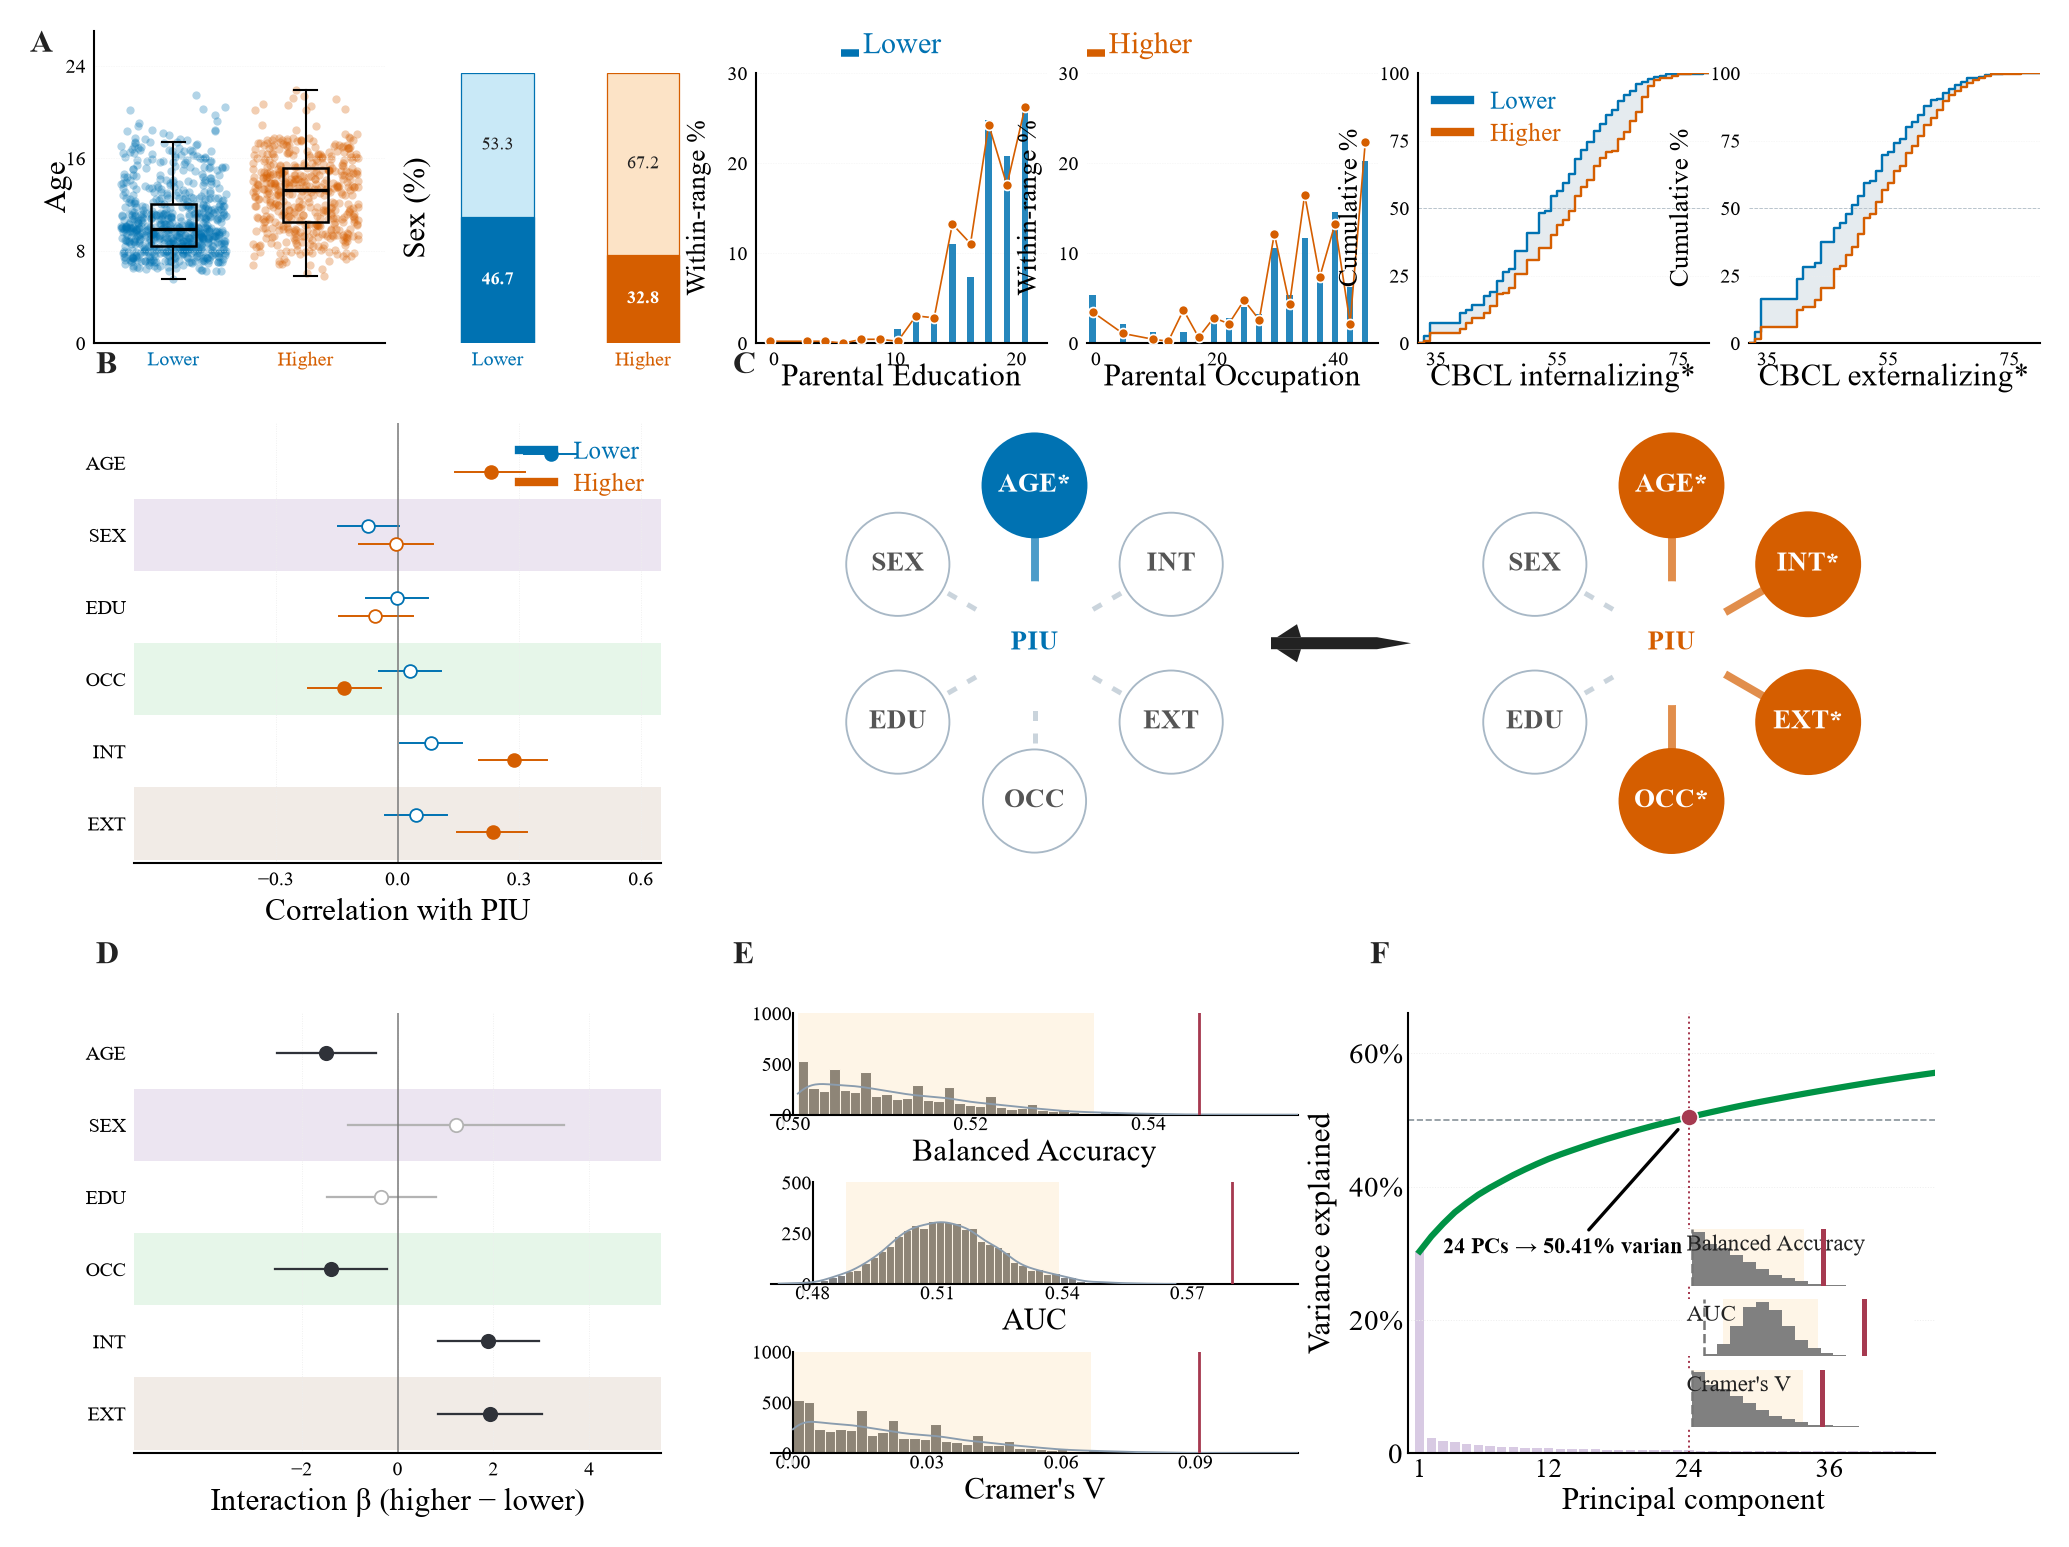


Wrote Figure 2 outputs to C:\Users\ai412\Desktop\Visualization_Figure_official_v1.1.4\3_Visualizations\results_figures:
  Figure2.png  339984 bytes
  Figure2.svg  303970 bytes
  Figure3.png  676043 bytes
  Figure3.svg  4143957 bytes
  Figure4.png  272740 bytes
  Figure4.svg  237078 bytes


In [5]:

# ---------------------------------------------------------------------------
# Style
# ---------------------------------------------------------------------------
INK_TEXT = COLORS['text']
LOW_COLOR = COLORS['low']
HIGH_COLOR = COLORS['high']

# The complete canvas is only 6.70 in wide (the per-panel exports are
# 10 in), so every label of a reused panel is shrunk to keep the typography
# of the reference intact.  The scales below were re-measured against the
# new 2009 x 895 reference.
A_SCALE = 0.55
B_SCALE = 0.55
C_SCALE = 1.00        # the map panels are drawn at their own size
DEF_SCALE = 0.65

# Stroke widths need their own factor: the reference was laid out with
# hairline strokes, the per-panel exports use the original (thicker) ones.
A_LW = 0.25
B_LW = 0.36
C_LW = 0.50
DEF_LW = 0.45
F_LW = 0.40

# Sizes that the reference sets independently of the panels' own scale.
A_XLABEL_SIZE = 7.5
A_TICK_PAD = 2.0      # the reference sets the tick labels very close
A_XLABEL_PAD = -1.5  # the axis caption clears band B's first row
B_XLABEL_SIZE = 7.5
B_TICK_PAD = 2.0
B_XLABEL_PAD = 2.0    # the axis caption almost touches the tick labels
B_Q_SIZE = 6.0
MAP_NAME_SIZE = 6.5
MAP_VALUE_SIZE = 5.5
MAP_IAT_SIZE = 6.5
MAP_SCORE_SIZE = 6.0
DEF_OBS_SIZE = 6.5
DEF_METRIC_SIZE = 7.0
DEF_XLABEL_SIZE = 7.5
E_XTICK_SIZE = 6.5  # the permutation panels label their axis a little larger
E_OBS_X = 1.0        # the observed caption sits flush with the axes' edge
E_TICK_PAD = 0.30
G_XTICK_SIZE = 6.5
G_TICK_PAD = 1.26
DEF_XLABEL_PAD = 1.0
INSET_LABEL_SIZE = 5.5   # F 内嵌的 x 标题略小，给三条内嵌之间再腾一点空间
INSET_P_SIZE = 5.5
INSET_LABEL_X = -0.05
INSET_P_X = 1.02
E_NOTE_Y = 0.891
E_NOTE_X = 0.060
E_NOTE_SIZE = 7.0
E_XLABEL_SIZE = 7.5
E_XLABEL_PAD = 1.0
E_YTICK_SIZE = 7.0
F_XTICK_SIZE = 6.5
F_TICK_PAD = 1.2

LETTER_SIZE = 7.7     # ~24 px cap height in the reference
LEGEND_SIZE = 3.62
CAPTION_SIZE = 3.55   # (the new reference carries no "Association map")

# The bottom spines of the six A panels: v0.8.24 — every visible axis
# line of the three figures is now the same black 0.5 pt line, so the
# Age panel's pale hairline is gone.  The Male-sex panel keeps no spine
# at all (the reference leaves it open).
A_SPINE_BLACK = '#000000'
A_SPINES = (
    (A_SPINE_BLACK, BASELINE_LW_PT),   # Age
    (None, 0.0),                       # Male sex
    (A_SPINE_BLACK, BASELINE_LW_PT),   # Parental education
    (A_SPINE_BLACK, BASELINE_LW_PT),   # Parental occupation
    (A_SPINE_BLACK, BASELINE_LW_PT),   # CBCL internalizing
    (A_SPINE_BLACK, BASELINE_LW_PT),   # CBCL externalizing
)

# ---------------------------------------------------------------------------
# Canvas + layout (all numbers are reference pixels of fig1v2.png)
# ---------------------------------------------------------------------------
REF_W = 2009.0
REF_H = 1560.0
FIG_W = REF_W / 300.0
FIG_H = REF_H / 300.0

# ---- Band A : compressed 1 x 6 row -------------------------------------
A_COLUMNS = (
    (63.0, 353.9),      # col 1: Age
    (393.9, 684.8),     # col 2: Male sex
    (724.8, 1015.8),    # col 3: Parental education
    (1055.8, 1346.7),   # col 4: Parental occupation
    (1386.7, 1677.7),   # col 5: CBCL internalizing
    (1717.7, 2008.6),   # col 6: CBCL externalizing
)
# The A band is one row of six panels.  v0.8.12 — the Age panel is
# 42 px taller than the other five: the group legend has moved to the
# Parental Education panel (the age clouds name their group on the x
# axis), so the strip above the Age panel is free and the extra height
# gives the age cloud more room.  Its top (y = 8) is level with the
# panel letter 'A'.
A_ROWS = (
    (8.0, 320.0),    # col 1: Age
    (50.0, 320.0),   # col 2: Male sex
    (50.0, 320.0),   # col 3: Parental education
    (50.0, 320.0),   # col 4: Parental occupation
    (50.0, 320.0),   # col 5: CBCL internalizing
    (50.0, 320.0),   # col 6: CBCL externalizing
)

# Group brace + asterisk, in reference pixels: (brace x, asterisk x).
A_BRACKET_PX = {
    'Age': (46.0, 21.0),
    'Male sex': (46.0, 21.0),
}
A_TITLE_PAD = 5.8
A_YLABEL_SIZE = 6.5

# ---- Three columns, shared by both lower bands -------------------------
# 3 columns of 607 px with 30 px gutters:
#   63 + 607 + 30 + 607 + 30 + 607 + 65 = 2009
COL1 = (63.0, 670.0)      # B (row 1) / D (row 2)  ← same column → vertical
COL2 = (700.0, 1307.0)    # C_low (row 1) / E (row 2)
COL3 = (1337.0, 1944.0)   # C_high (row 1) / F (row 2)

# Two y bands; 520 px tall each (B / D / E / F all share the same height).
ROW1_TOP, ROW1_BOT = 360.0, 880.0
ROW2_TOP, ROW2_BOT = 950.0, 1470.0

# ---- Band row 1 : B in COL1, C_low in COL2, C_high in COL3 --------------
B_LEFT = (COL1[0], COL1[1], ROW1_TOP, ROW1_BOT)
C_LOW  = (COL2[0], COL2[1], ROW1_TOP, ROW1_BOT)
C_HIGH = (COL3[0], COL3[1], ROW1_TOP, ROW1_BOT)
# Arrow: from the right edge of C_low, through the 30 px gutter, to the
# left edge of C_high.  Drawn at the vertical centre of the C row.
C_ARROW_X0 = C_LOW[1]  + 2.0      # 1309
C_ARROW_X1 = C_HIGH[0] - 2.0      # 1335
C_ARROW_Y  = (ROW1_TOP + ROW1_BOT) / 2.0   # 620

C_ROCKET_X0 = 1240.0
C_ROCKET_X1 = 1380.0
C_ROCKET_HALF = 6.0        # the body's half width
C_ROCKET_FIN = 13.0        # how far the fins stick out

# ---- Band row 2 : D in COL1 (under B), E in COL2, F in COL3 ------------
D_LEFT  = (COL1[0], COL1[1], ROW2_TOP, ROW2_BOT)
E_PANEL = (COL2[0], COL2[1], ROW2_TOP, ROW2_BOT)
F_MAIN  = (COL3[0], COL3[1], ROW2_TOP, ROW2_BOT)

# The three E histograms as fractions of the E column's height: the first
# is 120 px of the 520 px column, then an 80 px gap, and so on.
E_ROW_FRACTIONS = (
    (0.0000, 0.2308),   # 0.00 - 0.23   (120 px)
    (0.3846, 0.6154),   # 0.38 - 0.62   (200 - 320 px)
    (0.7692, 1.0000),   # 0.77 - 1.00   (400 - 520 px)
)

PANEL_INSET = 40.0

# ---- Panel letters -----------------------------------------------------
# B / D sit on the same x column, so their letters line up vertically.
LETTER_A = (-1.0, 28.5)
LETTER_B = (COL1[0] + 2.0, ROW1_TOP - 10.0)   # ( 65, 350)
LETTER_C = (COL2[0] + 2.0, ROW1_TOP - 10.0)   # (702, 350)
LETTER_D = (COL1[0] + 2.0, ROW2_TOP - 10.0)   # ( 65, 910)  ← same x as B
LETTER_E = (COL2[0] + 2.0, ROW2_TOP - 10.0)   # (702, 910)
LETTER_F = (COL3[0] + 2.0, ROW2_TOP - 10.0)   # (1339, 910)

# The group legend sits above the Parental Education panel, not above the
# Age panel: the age clouds name their group on the x axis ('L-S' /
# 'H-S'), so they do not need the key, while the SES panels do.
LEGEND_LOW  = (810.0, 30.0)
LEGEND_HIGH = (1055.8, 30.0)
LEGEND_SIZE = 7.2
LEGEND_SWATCH_PX = 18.0

PANEL_DRAWERS = ('draw_a_grid', 'draw_forest_corr', 'draw_forest_inter',
                 'draw_assoc_map', 'draw_d_stack', 'draw_e', 'draw_f_stack')


def _apply_rcparams() -> None:
    mpl.rcParams.update({
        'font.family': 'serif',
        'font.serif': ['Times New Roman'],
        'mathtext.fontset': 'stix',
        'svg.fonttype': 'none',
        'pdf.fonttype': 42,
        'figure.facecolor': 'white',
        'axes.facecolor': 'white',
    })


_apply_rcparams()


# ---------------------------------------------------------------------------
# Geometry helpers
# ---------------------------------------------------------------------------
def _fx(px: float) -> float:
    """Reference pixel (from the left) -> figure fraction."""
    return px / REF_W


def _fy(px: float) -> float:
    """Reference pixel (from the top) -> figure fraction (from the bottom)."""
    return 1.0 - px / REF_H


def _fig_line_px(fig, x0: float, x1: float, y: float, color, lw: float = 1.8,
                 zorder: int = 13):
    """A horizontal line in reference pixels (the A band legend swatches)."""
    from matplotlib.lines import Line2D
    line = Line2D([_fx(x0), _fx(x1)], [_fy(y), _fy(y)],
                  transform=fig.transFigure, color=color, lw=lw,
                  solid_capstyle='butt', clip_on=False, zorder=zorder)
    fig.add_artist(line)
    return line


def _rect(x0: float, x1: float, y0: float, y1: float):
    """(x0, x1, y0, y1) in reference px -> matplotlib axes position."""
    return [_fx(x0), _fy(y1), _fx(x1) - _fx(x0), _fy(y0) - _fy(y1)]


def _inset(rect, d: float = PANEL_INSET):
    """Shrink a panel rectangle by ``d`` reference pixels on every side.

    The inset is symmetric, so the panel keeps the centre of its cell —
    the letters and the neighbouring panels stay aligned.
    """
    x0, x1, y0, y1 = rect
    return (x0 + d, x1 - d, y0 + d, y1 - d)


def _e_rows(box):
    """The three E histograms inside the (inset) E column ``box``."""
    y0, y1 = box[2], box[3]
    height = y1 - y0
    return [(y0 + f0 * height, y0 + f1 * height)
            for f0, f1 in E_ROW_FRACTIONS]


def _offset_xlabel(ax, dx_px: float) -> None:
    """Shift the x-axis caption of ``ax`` horizontally.

    The reference places the captions of panels E, F and G by hand rather
    than centring them on their axes, so they are nudged here to land on
    the reference pixels.
    """
    from matplotlib.transforms import ScaledTranslation
    transform = ax.xaxis.label.get_transform()
    ax.xaxis.label.set_transform(
        transform + ScaledTranslation(dx_px / 300.0, 0.0,
                                      ax.figure.dpi_scale_trans))


def _need(ns: Mapping[str, object], name: str):
    try:
        return ns[name]
    except KeyError:
        raise KeyError(
            f'fig1(完整版): {name!r} is missing from the caller namespace.'
        ) from None


def _panel_drawers(ns: Mapping[str, object]) -> Mapping[str, object]:
    """Return a namespace that surely contains the panel-drawing helpers.

    The helpers live in this same module, so the caller's namespace
    already carries them.
    """
    missing = [name for name in PANEL_DRAWERS if name not in ns]
    if not missing:
        return ns
    merged = dict(ns)
    merged.update({name: globals()[name] for name in PANEL_DRAWERS
                   if name in globals()})
    still = [name for name in PANEL_DRAWERS if name not in merged]
    if still:
        raise KeyError(
            f'fig1(完整版): the panel helpers could not be found: {still}.'
        )
    return merged


# ---------------------------------------------------------------------------
# The complete canvas
# ---------------------------------------------------------------------------
def build_complete_figure(ns: Optional[Mapping[str, object]] = None) -> plt.Figure:
    """Assemble the single Figure-1 canvas (band A / band C / band B-D-E-F).

    Layout
    ------
    row 0   A  band  (six sub-panels, compressed height)
    row 1   C  band  (two association maps + arrow between them)
    row 2   B | D | E | F  (four equal panels, same y band, same height)
    """
    if ns is None:
        ns = sys.modules['__main__'].__dict__
    ns = _panel_drawers(ns)

    draw_a_grid = _need(ns, 'draw_a_grid')
    draw_forest_corr = _need(ns, 'draw_forest_corr')
    draw_forest_inter = _need(ns, 'draw_forest_inter')
    draw_assoc_map = _need(ns, 'draw_assoc_map')
    draw_d_stack = _need(ns, 'draw_d_stack')
    draw_e = _need(ns, 'draw_e')
    draw_f_stack = _need(ns, 'draw_f_stack')
    low_color = ns.get('low_color', LOW_COLOR)
    high_color = ns.get('high_color', HIGH_COLOR)

    fig = plt.figure(figsize=(FIG_W, FIG_H), dpi=300, facecolor='white')

    # ---------------- band A : six sub-panels (1 x 6) --------------------
    ax_a = [[fig.add_axes(_rect(A_COLUMNS[c][0], A_COLUMNS[c][1],
                                 A_ROWS[c][0], A_ROWS[c][1]))
             for c in range(6)]]
    draw_a_grid(ax_a, scale=A_SCALE, rasterized=False, letter_prefix='',
                title_pads=(A_TITLE_PAD,) * 6,
                spine_specs=A_SPINES, bracket_kw={},
                xlabel_size=A_XLABEL_SIZE, tick_pad=A_TICK_PAD,
                xlabel_pad=A_XLABEL_PAD, lw_scale=A_LW)

    # ---------------- band C : two association maps on their own row -----
    ax_map = fig.add_axes(_rect(*C_LOW))
    ax_map_high = fig.add_axes(_rect(*C_HIGH))
    draw_assoc_map(ax_map, 'Low-IAT', low_color, scale=C_SCALE, stars=True,
                   name_size=MAP_NAME_SIZE, value_size=MAP_VALUE_SIZE,
                   iat_size=MAP_IAT_SIZE, score_size=MAP_SCORE_SIZE,
                   lw_scale=C_LW)
    draw_assoc_map(ax_map_high, 'High-IAT', high_color, scale=C_SCALE,
                   stars=True, name_size=MAP_NAME_SIZE,
                   value_size=MAP_VALUE_SIZE, iat_size=MAP_IAT_SIZE,
                   score_size=MAP_SCORE_SIZE, lw_scale=C_LW)
    from matplotlib.patches import Polygon
    rx0, rx1 = C_ROCKET_X0, C_ROCKET_X1
    rcy = C_ARROW_Y
    rh = C_ROCKET_HALF
    body = [(rx0, rcy - rh), (rx1 - 34, rcy - rh), (rx1, rcy),
            (rx1 - 34, rcy + rh), (rx0, rcy + rh)]
    fin_top = [(rx0 + 6, rcy - rh), (rx0 + 26, rcy - rh - C_ROCKET_FIN),
               (rx0 + 30, rcy - rh)]
    fin_bottom = [(rx0 + 6, rcy + rh), (rx0 + 26, rcy + rh + C_ROCKET_FIN),
                  (rx0 + 30, rcy + rh)]
    for points in (fin_top, body, fin_bottom):
        fig.patches.append(Polygon(
            [(_fx(x), _fy(y)) for x, y in points],
            closed=True, facecolor=INK_TEXT, edgecolor='none',
            transform=fig.transFigure, clip_on=False, zorder=13))

    # ---------------- band B / D / E / F : four equal panels -------------
    ax_b = fig.add_axes(_rect(*_inset(B_LEFT)))
    ax_d = fig.add_axes(_rect(*_inset(D_LEFT)))
    e_box = _inset(E_PANEL)
    ax_e_stack = [fig.add_axes(_rect(e_box[0], e_box[1], y0, y1))
                  for (y0, y1) in _e_rows(e_box)]
    ax_f = fig.add_axes(_rect(*_inset(F_MAIN)))

    # B forest: no asterisks in the row labels any more.
    draw_forest_corr(ax_b, scale=B_SCALE, title=None, stars=False,
                     xlabel_size=B_XLABEL_SIZE, tick_pad=B_TICK_PAD,
                     xlabel_pad=B_XLABEL_PAD, lw_scale=B_LW)

    # D forest: same treatment.
    draw_forest_inter(ax_d, scale=B_SCALE, title=None, stars=False,
                      xlabel_size=B_XLABEL_SIZE, q_size=B_Q_SIZE,
                      tick_pad=B_TICK_PAD, xlabel_pad=B_XLABEL_PAD,
                      lw_scale=B_LW)

    # E: the three full-sample permutation histograms.
    draw_d_stack(ax_e_stack, scale=DEF_SCALE, title=None,
                 obs_size=DEF_OBS_SIZE, metric_size=DEF_METRIC_SIZE,
                 xlabel_size=DEF_XLABEL_SIZE,
                 tick_pad=E_TICK_PAD, xlabel_pad=DEF_XLABEL_PAD,
                 xtick_size=E_XTICK_SIZE, obs_x=E_OBS_X, lw_scale=DEF_LW)

    # F: the PC-variance main plot with the three PC24 null histograms
    # back inside the body (draw_insets=True is the default; we say it
    # explicitly so the intent is clear).
    draw_e(ax_f, scale=DEF_SCALE, title=None, draw_insets=True,
           note_size=E_NOTE_SIZE, xlabel_size=E_XLABEL_SIZE,
           xtick_size=F_XTICK_SIZE, ytick_size=E_YTICK_SIZE,
           tick_pad=F_TICK_PAD, xlabel_pad=E_XLABEL_PAD,
           lw_scale=F_LW, note_y=E_NOTE_Y, note_x=E_NOTE_X)
    _offset_xlabel(ax_f, 22.0)

    # ---------------- panel letters --------------------------------------
    for (x, baseline), letter in (
        (LETTER_A, 'A'), (LETTER_B, 'B'), (LETTER_C, 'C'),
        (LETTER_D, 'D'), (LETTER_E, 'E'), (LETTER_F, 'F'),
    ):
        fig.text(_fx(x), _fy(baseline), letter,
                 fontsize=LETTER_SIZE, fontweight='bold', color=INK_TEXT,
                 ha='left', va='baseline')

    # ---------------- top legend (the band A title) ----------------------
    for x0, color, text in ((LEGEND_LOW[0], low_color, 'Lower'),
                            (LEGEND_HIGH[0], high_color, 'Higher')):
        _fig_line_px(fig, x0, x0 + LEGEND_SWATCH_PX, LEGEND_LOW[1], color)
        fig.text(_fx(x0 + LEGEND_SWATCH_PX + 4.0), _fy(LEGEND_LOW[1]), text,
                 fontsize=LEGEND_SIZE, color=color, ha='left', va='baseline')

    return fig


# ---------------------------------------------------------------------------
# Public entry point
# ---------------------------------------------------------------------------
def make_figure(export: bool = False,
                output_dir=None,
                state: Optional[Mapping[str, object]] = None) -> plt.Figure:
    """Build the complete Figure-1 canvas.

    Returns the matplotlib Figure.  When ``export=True`` the PNG/SVG pair
    ``Figure2.png`` / ``Figure2.svg`` is written to ``output_dir``
    (default: the env var ``FIGURE1_V2_OUTPUT_DIR`` or the repository's
    ``3_Visualizations/results_figures/``).

    Reads the upstream names from ``state`` (tests) or the caller's
    ``sys.modules['__main__'].__dict__`` (runpy / notebook flow).
    """
    ns = state if state is not None else sys.modules['__main__'].__dict__
    fig = build_complete_figure(ns)

    if export:
        if output_dir is None:
            output_dir = os.environ.get(
                'FIGURE1_V2_OUTPUT_DIR',
                str(RESULTS_DIR),
            )
        out = Path(output_dir)
        out.mkdir(parents=True, exist_ok=True)
        png_path = out / 'Figure2.png'
        svg_path = out / 'Figure2.svg'
        # No bbox_inches='tight' — the complete canvas has a fixed
        # 6.6967 x 2.9833 in geometry that must not be re-cropped.
        fig.savefig(png_path, dpi=300, facecolor='white')
        fig.savefig(svg_path, facecolor='white', metadata={'Date': None})
        print(f'  wrote {png_path}  ({png_path.stat().st_size / 1024:.0f} KB)')
        print(f'  wrote {svg_path}  ({svg_path.stat().st_size / 1024:.0f} KB)')

    return fig




# --- the one-shot complete canvas ---------------------------------------
# The per-panel canvases (Figure2_A/BC/DF/Map_V2) are no longer produced:
# the complete figure is the only artefact.  The composite receives this
# module's namespace so that it can reuse the panel helpers above and the
# data that was computed above.
out_dir = str(RESULTS_DIR)
os.makedirs(out_dir, exist_ok=True)
fig_complete = build_complete_figure(globals())
# NOTE: no bbox_inches='tight' — the complete canvas has a fixed
# 6.697 x 5.200 in geometry (2009 x 1560 px) that must not be re-cropped,
# otherwise the SVG would no longer match the reference layout.
fig_complete.savefig(os.path.join(out_dir, 'Figure2.png'), dpi=300,
                     facecolor='white')
fig_complete.savefig(os.path.join(out_dir, 'Figure2.svg'), facecolor='white',
                     metadata={'Date': None})

plt.show()

print('\nWrote Figure 2 outputs to ' + out_dir + ':')
for f in sorted(os.listdir(out_dir)):
    if f.endswith(('.svg', '.png')):
        size = os.path.getsize(os.path.join(out_dir, f))
        print('  ' + f + '  ' + str(size) + ' bytes')


**Figure 2 | Behavioural characteristics and global FC alignment across IAT groups.** **A,** Group distributions in the same 1,114 participants (low-IAT, n = 653; high-IAT, n = 461). Age shows every participant alongside median, interquartile range, and 1.5 × IQR whiskers. CBCL panels show empirical cumulative distribution functions (ECDFs): at each T score, each step gives the percentage of participants in that IAT group scoring at or below that value. The shaded region highlights separation between the two group curves. Parental education and occupation show within-group percentages at each observed Barratt score. Sex retains the male/female proportional-bar display (sex coded 1 for male). Labels show Benjamini–Hochberg-adjusted q values from six group comparisons (Welch t tests for age and CBCL scores, Fisher's exact test for sex, and Mann–Whitney U tests for parental socioeconomic scores). **B,** Within-group associations between continuous IAT scores and behavioural characteristics. Pearson's *r* is used for age and CBCL scores, point-biserial *r* for sex (coded 1 for male and 0 for female), and Spearman's rho for parental education and occupation. The adjoining association maps repeat these six characteristics in fixed positions. Solid coloured connections mark within-range associations with FDR-adjusted *q* < 0.05; pale dashed connections mark associations that did not pass this threshold. Purple marks the negative occupation association in the high-IAT range. The maps summarize IAT–characteristic associations and do not represent a behavioural network. **C,** Direct group-by-characteristic interaction coefficients from separate ordinary least-squares models with HC3 robust standard errors; positive values indicate a stronger positive slope in the high-IAT group. Squares denote the binary sex variable in B and C. Filled symbols in B and C denote FDR-adjusted *q* < 0.05 and horizontal lines denote 95% confidence intervals. The Benjamini–Hochberg procedure was applied across 12 within-group associations in B and six interaction tests in C.

**D,** Histograms show null distributions from 5,000 IAT-label permutations for PC1–PC50 GMM alignment. Orange solid lines indicate observed values. Blue dotted lines indicate the 2.5th and 97.5th percentiles of the permutation null distributions; shading marks the central 95% interval, not a confidence interval for the observed statistic. Cluster labels were oriented towards the group with greater high-IAT enrichment in both the observed and permuted data. Consequently, balanced accuracy was bounded below by 0.50, producing a folded permutation null distribution. **E,** Bars and the blue curve show individual and cumulative FC variance explained by the principal components. The horizontal dashed line marks 50% cumulative variance, and the vertical orange dotted line identifies PC24, which explained 50.41% of the variance. The lower-right miniatures show the corresponding PC1–PC24 permutation tests, with the same percentile and observed-value encodings as in D. **F,** Histograms show BA, AUC and Cramér's V across 500 stratified 80% participant subsamples. Orange solid lines indicate the full-sample observed values. The two blue dotted lines indicate the 2.5th and 97.5th percentiles of the subsampling distributions. Text annotations report the median followed by these percentiles in brackets. BA, balanced accuracy; AUC, area under the receiver operating characteristic curve; V, Cramér's V.
